# Análisis y clasificación de textos

Proyecto final · 20 Newsgroups

**Pregunta central:** ¿qué aporta la representación léxica, la estructura temática descubierta sin etiquetas y la complejidad de los modelos a la clasificación de documentos?

El recorrido va de la representación a los grupos, luego a los clasificadores de referencia y culmina en una ablación que combina ambos enfoques.

Esta notebook integra los resultados guardados. Para reproducir desde cero, ejecutar python -m proyecto en el entorno Conda. No reajusta modelos ni usa prueba para elegir hiperparámetros.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
import seaborn as sns
sns.set_theme(style='whitegrid', palette='dark')
RESULTADOS = Path('resultados')

## 1. Preparación y representación de textos

### 1.1. Corpus y limpieza

Objetivo: descubrir temas sin etiquetas y clasificar documentos nuevos. Se emplea 20 Newsgroups: 3300 documentos en seis categorías, 2400 de entrenamiento y 900 de prueba. Se respeta la partición original y se selecciona un número fijo por categoría. Se eliminan cabeceras, firmas, citas, URL, correos y duplicados exactos. La tokenización conserva palabras inglesas y se excluyen palabras funcionales al vectorizar.

### Tabla: eda

In [2]:
tabla = pd.read_csv(RESULTADOS / 'experiment001' / 'eda.csv')
display(tabla.round(4))

,categoria,documentos,mediana_palabras,media_palabras,mediana_caracteres
0,Automóviles,400,71.0,129.7300,365.0
1,Espacio,400,86.0,184.6675,473.0
2,Gráficos,400,63.5,141.4600,338.5
3,Hockey,400,85.0,182.9600,456.5
4,Medicina,400,91.0,222.1700,507.5
5,Oriente Medio,400,138.0,340.4400,769.0


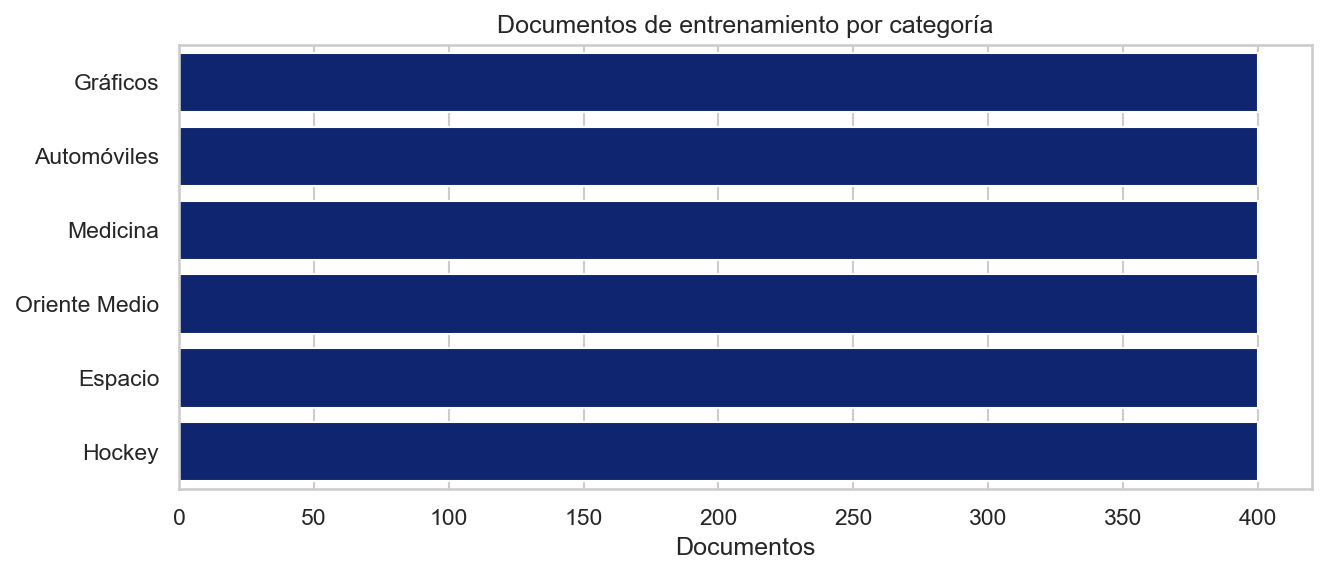

In [3]:
display(Image(filename='resultados/experiment001/01_categorias.png'))

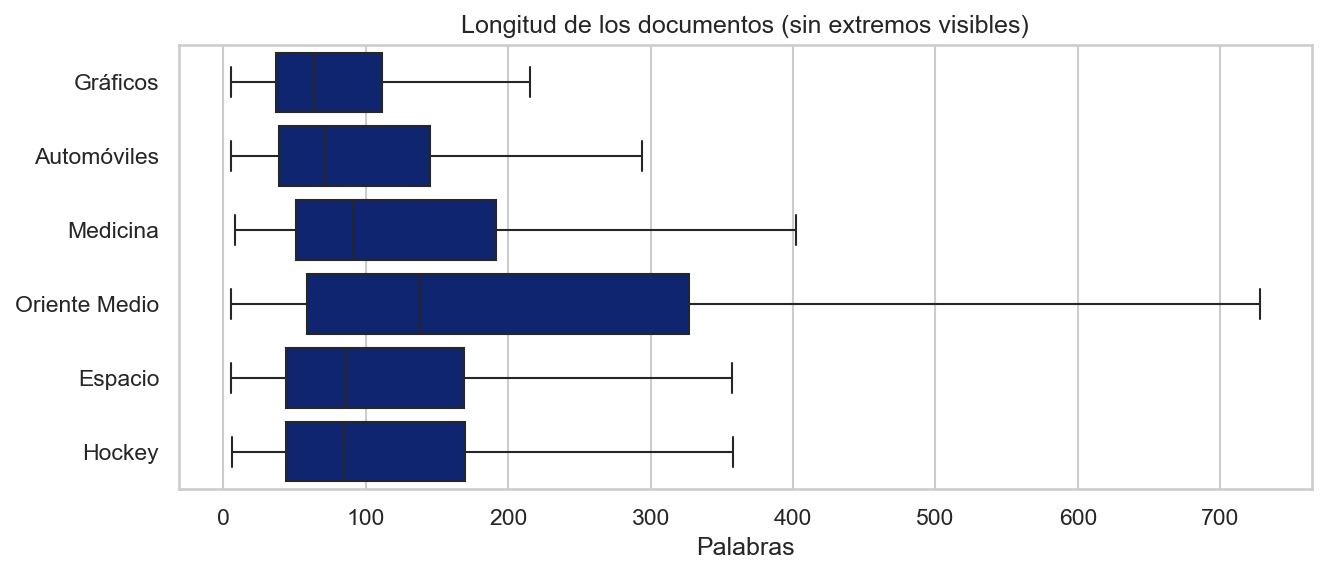

In [4]:
display(Image(filename='resultados/experiment001/02_longitudes.png'))

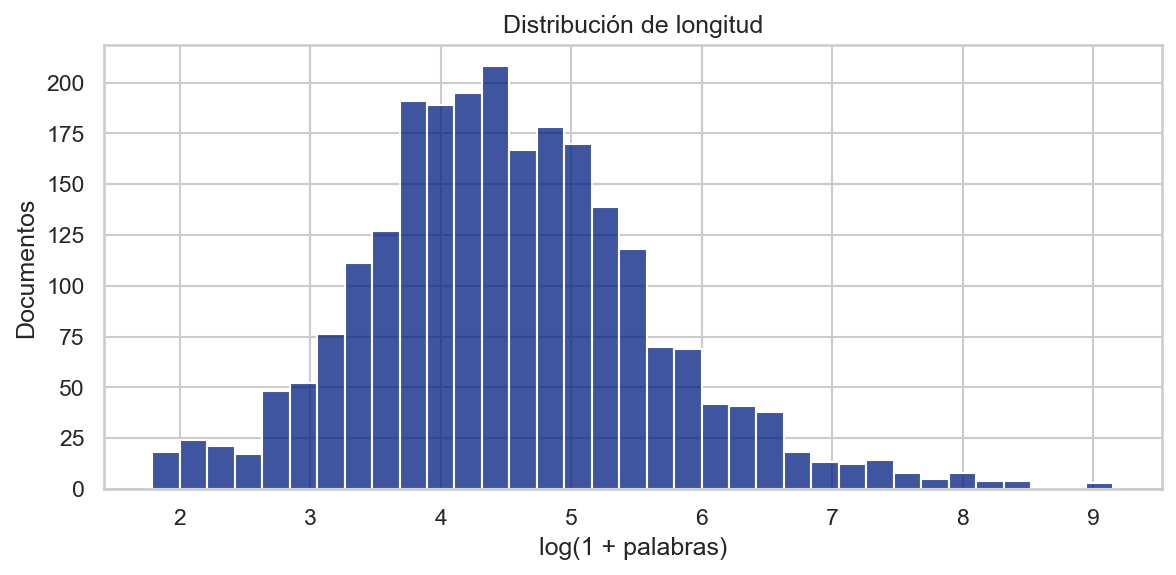

In [5]:
display(Image(filename='resultados/experiment001/03_histograma.png'))

### 1.2. ¿Cómo representar los documentos?

BoW representa frecuencias absolutas; TF-IDF pondera los términos por su frecuencia inversa documental suavizada y aplica normalización L2. El vocabulario se aprende únicamente del entrenamiento para el EDA supervisado. Los términos con frecuencia documental menor que dos se excluyen.

Las medianas de longitud por clase van de 64 a 138 palabras. Las matrices tienen 10,000–10,000 características y 99.42–99.42% de ceros. SVD con 100 componentes conserva 17.74% de la varianza según TruncatedSVD; al no centrarse la matriz, no equivale exactamente a PCA. La elevada esparsidad favorece algoritmos lineales y almacenamiento disperso.

### Tabla: representaciones

In [6]:
tabla = pd.read_csv(RESULTADOS / 'experiment001' / 'representaciones.csv')
display(tabla.round(4))

,representacion,documentos,caracteristicas,no_ceros,esparsidad
0,BoW,2400,10000,138733,0.9942
1,TF-IDF,2400,10000,138733,0.9942


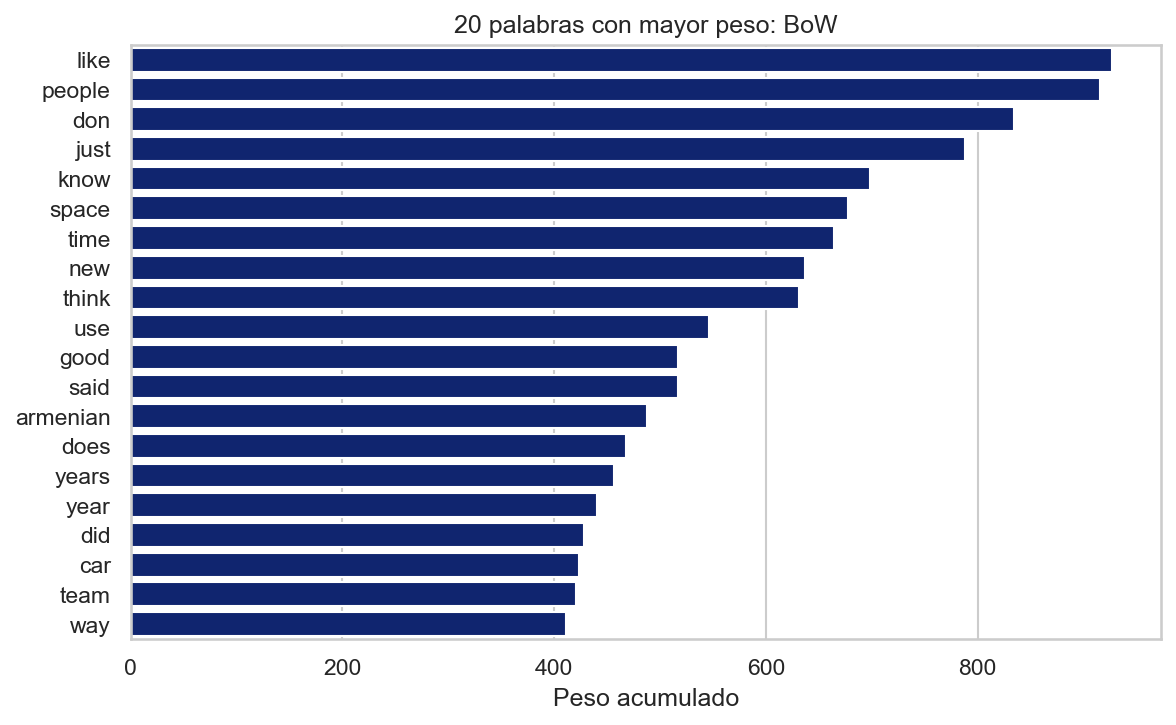

In [7]:
display(Image(filename='resultados/experiment001/04_terminos_BoW.png'))

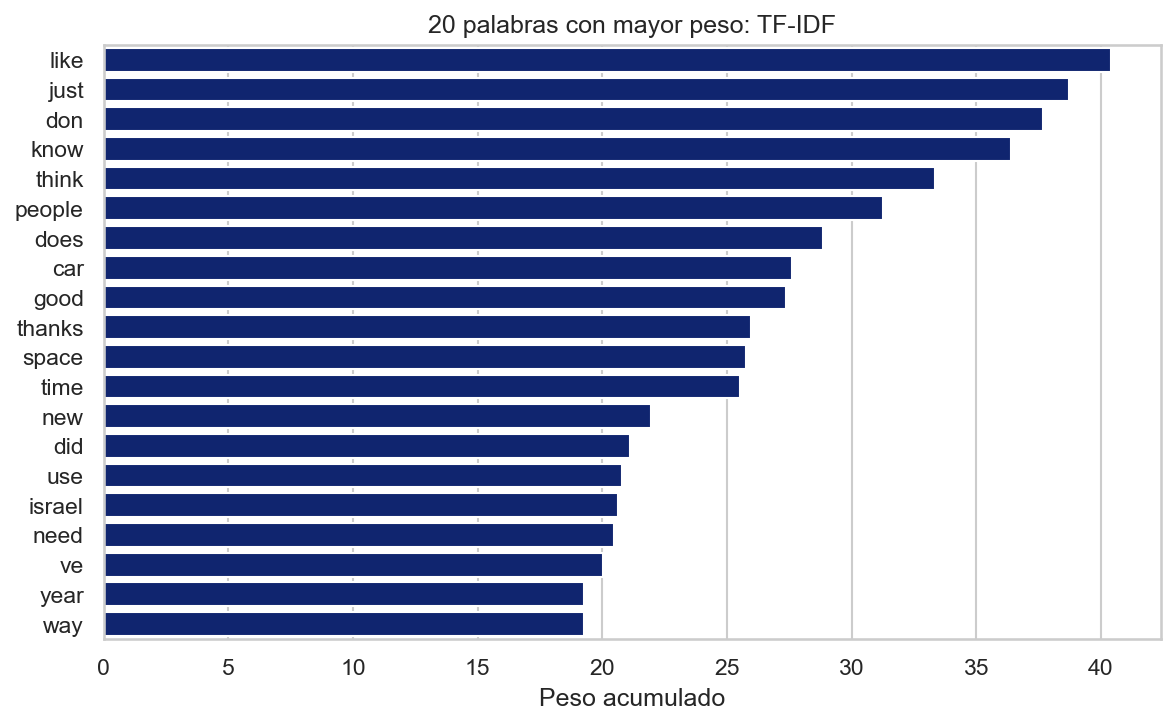

In [8]:
display(Image(filename='resultados/experiment001/04_terminos_TF-IDF.png'))

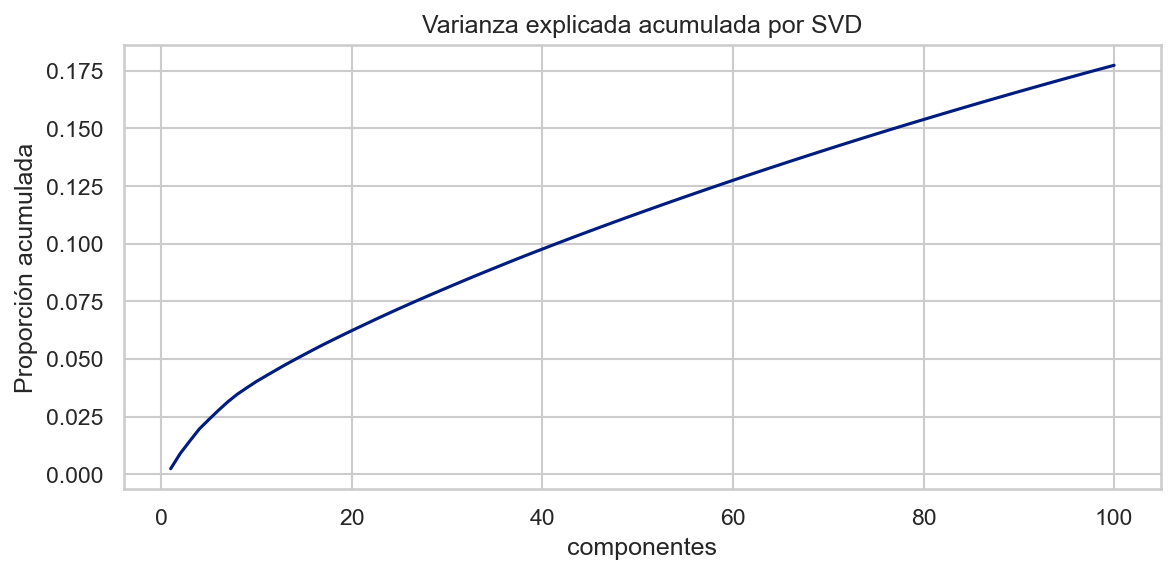

In [9]:
display(Image(filename='resultados/experiment001/05_varianza_svd.png'))

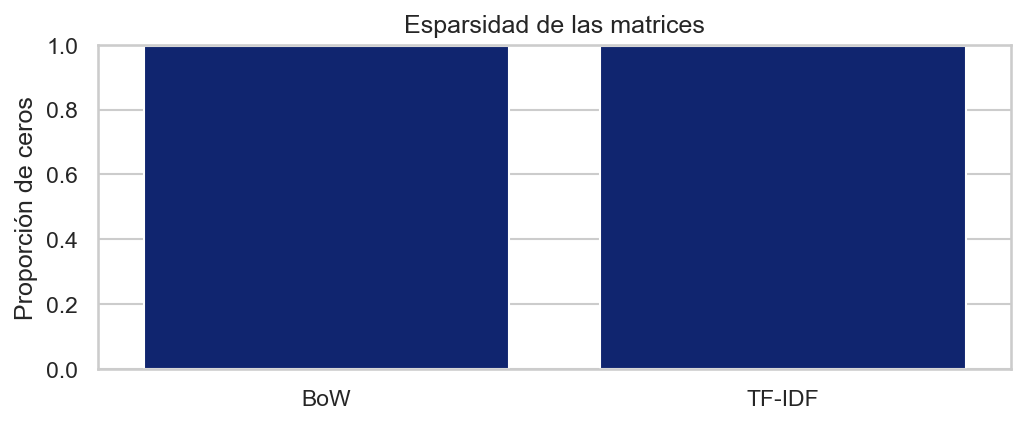

In [10]:
display(Image(filename='resultados/experiment001/06_esparsidad.png'))

## 2. Aprendizaje no supervisado

### 2.1. ¿Qué estructura temática emerge?

Se ajusta de forma independiente una representación TF-IDF en los mismos documentos del corpus completo, sin entregar las etiquetas a los estimadores. K-means minimiza dispersión euclidiana; el aglomerativo utiliza enlace promedio y distancia coseno; DBSCAN busca regiones densas y puede declarar ruido; la mezcla gaussiana usa EM, covarianzas diagonales y el espacio SVD-50. Se compara TF-IDF original y SVD normalizado cuando es viable. La proyección en dos componentes solo ilustra la geometría. Estos grupos constituyen la motivación para el experimento híbrido del capítulo 4; no se reutilizan sus asignaciones ajustadas sobre todo el corpus.

Se experimenta con k=3, 4, 6, 8 y 10 y, para DBSCAN, cinco radios y dos umbrales de vecinos. Silhouette coseno mide separación interna. Se excluye el ruido de su cálculo, se informa cobertura y se selecciona por cobertura × (1 + silhouette)/2 para penalizar el descarte. ARI y NMI se calculan únicamente después de congelar la selección; no se selecciona por las etiquetas.

La configuración seleccionada internamente es K-means, k=10, SVD-50: 10 grupos, cobertura 100.0%, silhouette 0.1534, ARI 0.4332 y NMI 0.5415. En contraste, el mayor ARI retrospectivo es 0.5038 (K-means, SVD-50, k=6). Un ARI cercano a cero señala concordancia ajustada por azar escasa; uno indica equivalencia perfecta. La geometría y las etiquetas temáticas no tienen por qué coincidir.

### Tabla: mejores

In [11]:
tabla = pd.read_csv(RESULTADOS / 'experiment002' / 'mejores.csv')
tabla = tabla[['algoritmo', 'representacion', 'parametros', 'grupos', 'cobertura', 'silhouette', 'ARI', 'NMI', 'segundos_ajuste']]
display(tabla.round(4))

,algoritmo,representacion,parametros,grupos,cobertura,silhouette,ARI,NMI,segundos_ajuste
0,K-means,SVD-50,k=10,10,1.0000,0.1534,0.4332,0.5415,2.0660
1,Mezcla gaussiana EM,SVD-50,k=10,10,1.0000,0.1102,0.3658,0.5436,2.4363
2,Aglomerativo,SVD-50,k=3,3,1.0000,0.0871,0.0009,0.0275,0.5679
3,K-means,TF-IDF,k=8,8,1.0000,0.0150,0.2162,0.4746,1.8831
4,Aglomerativo,TF-IDF,k=3,3,1.0000,0.0109,-0.0000,0.0012,0.5593
5,DBSCAN,TF-IDF,"eps=0.8, min=5",24,0.6418,-0.0084,0.0156,0.0662,1.8172
6,DBSCAN,SVD-50,"eps=0.2, min=5",40,0.4197,0.2172,0.0718,0.3582,2.7270


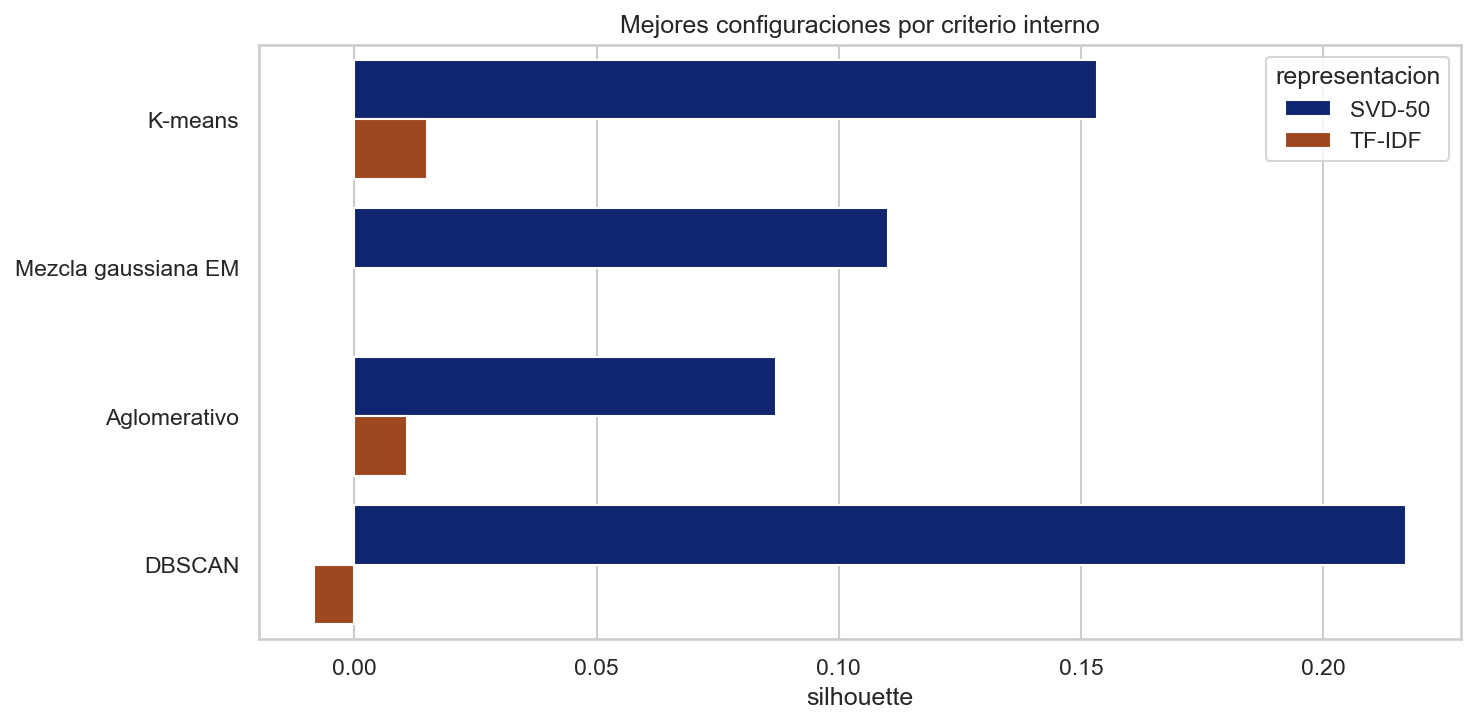

In [12]:
display(Image(filename='resultados/experiment002/01_silhouette.png'))

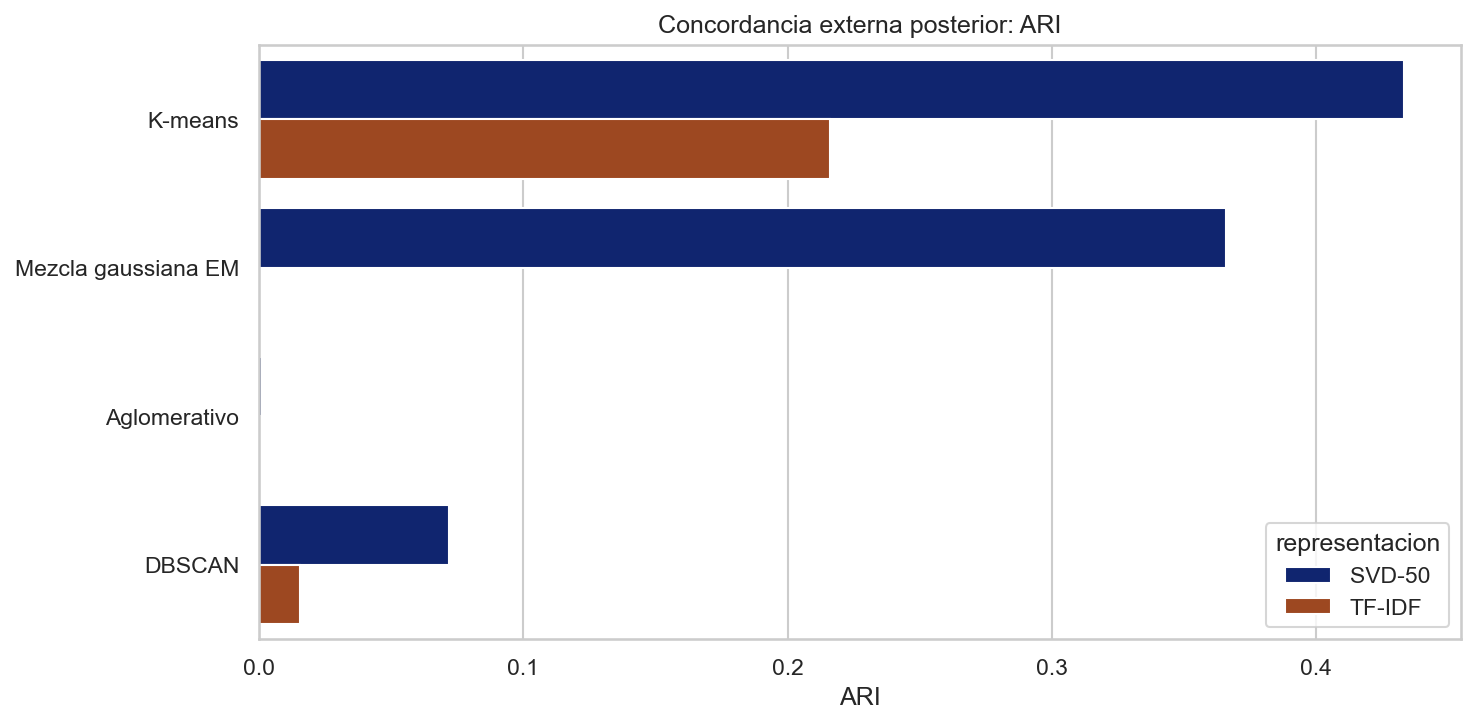

In [13]:
display(Image(filename='resultados/experiment002/02_ari.png'))

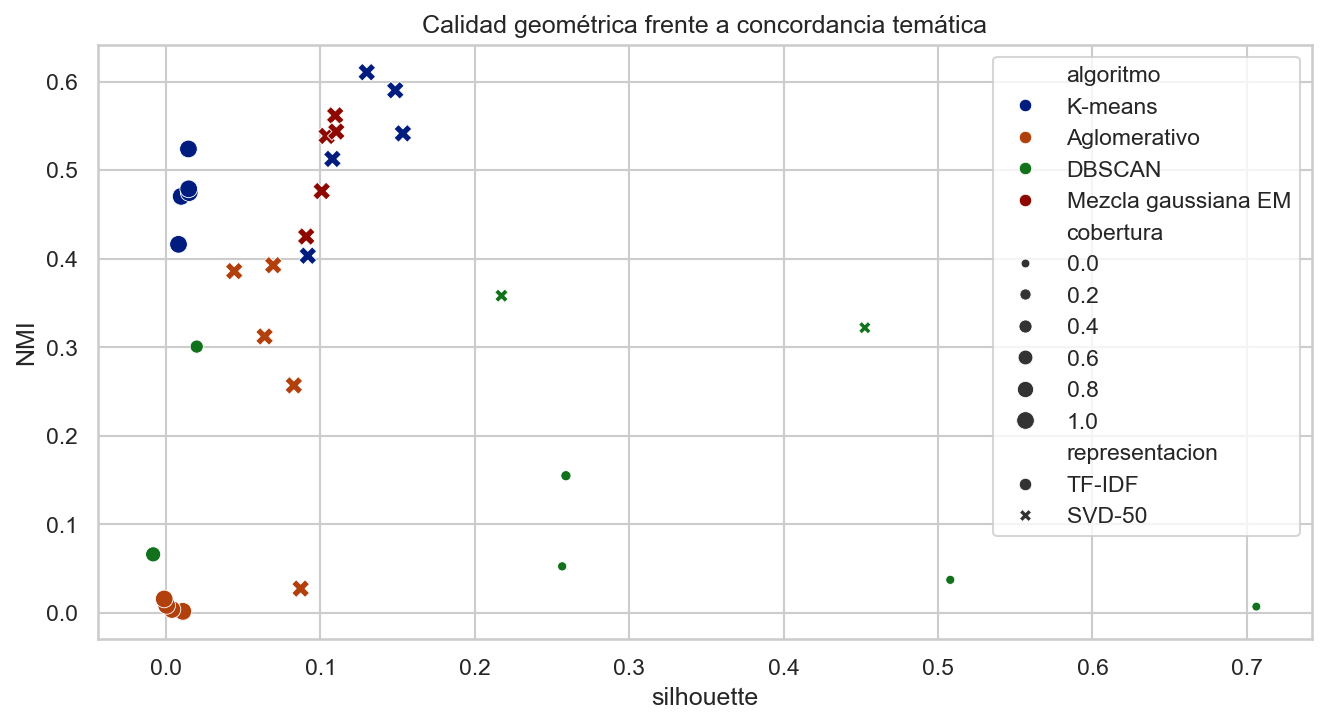

In [14]:
display(Image(filename='resultados/experiment002/03_concordancia.png'))

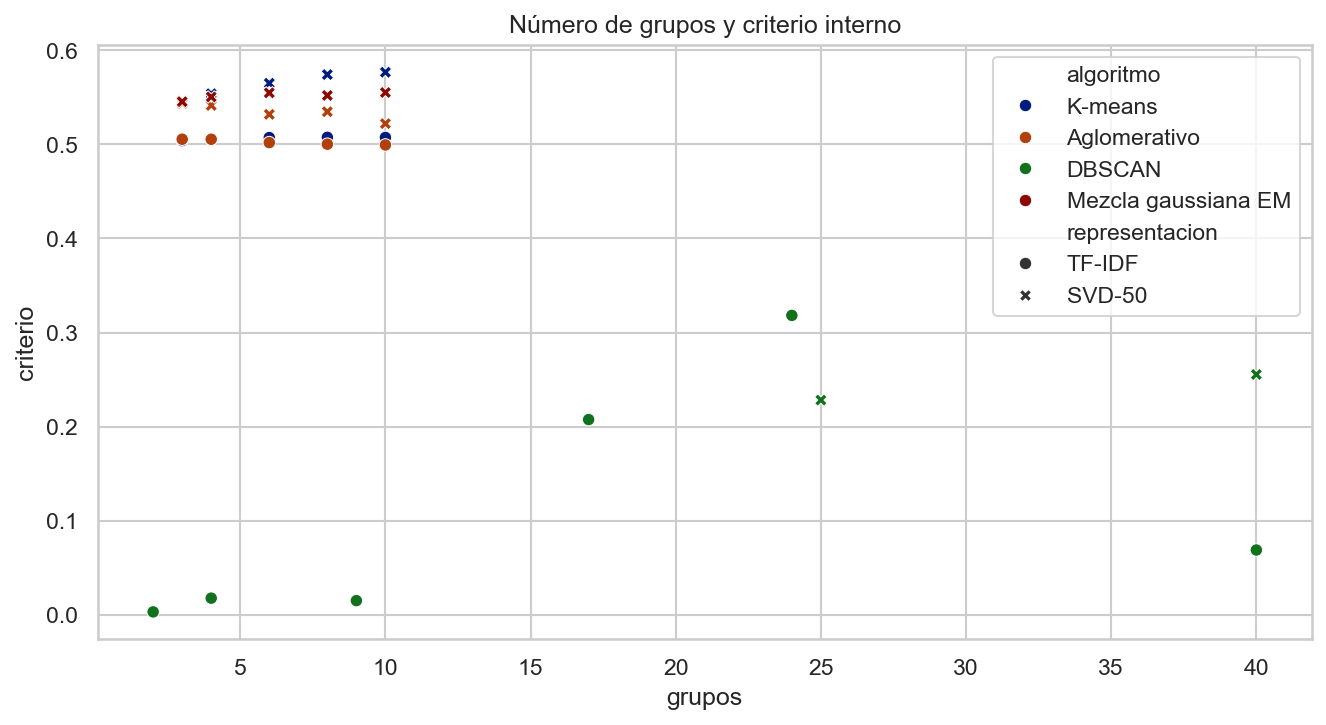

In [15]:
display(Image(filename='resultados/experiment002/04_numero_grupos.png'))

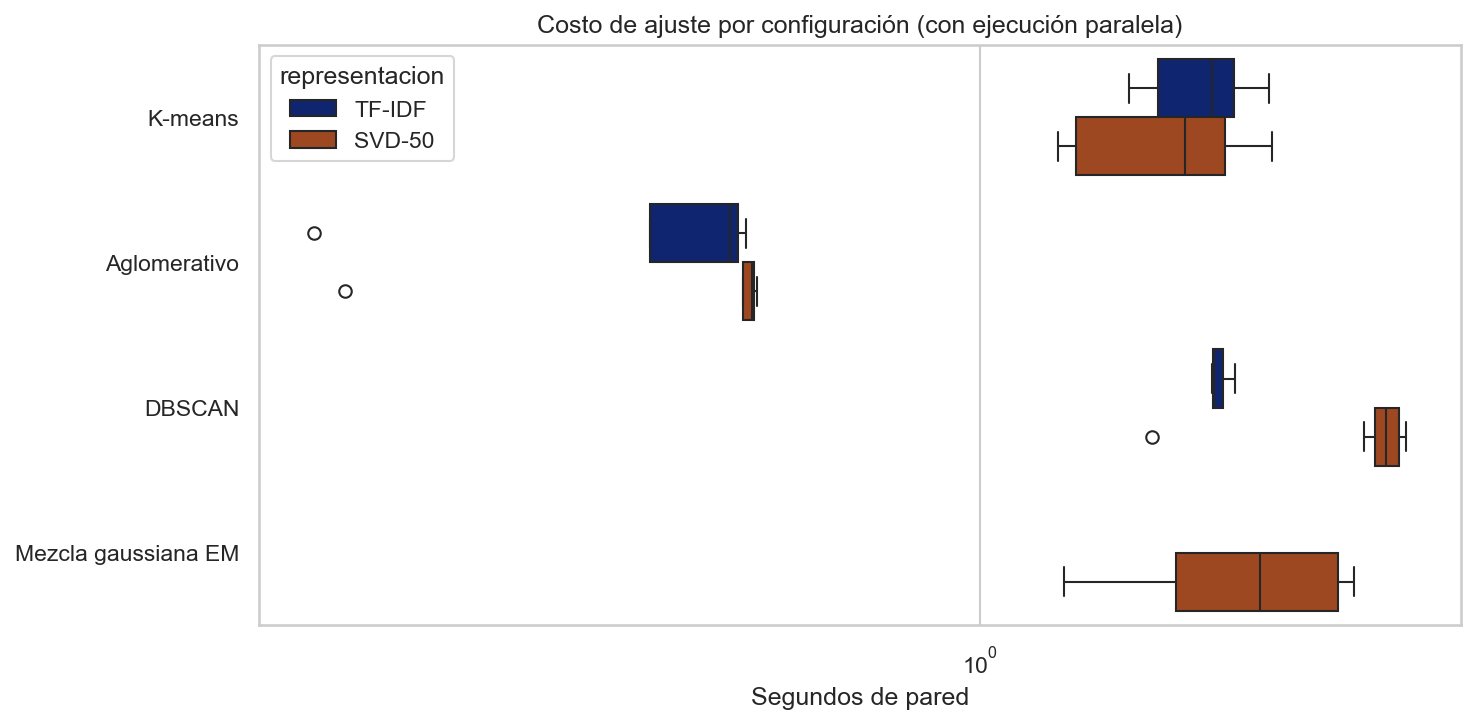

In [16]:
display(Image(filename='resultados/experiment002/07_tiempos.png'))

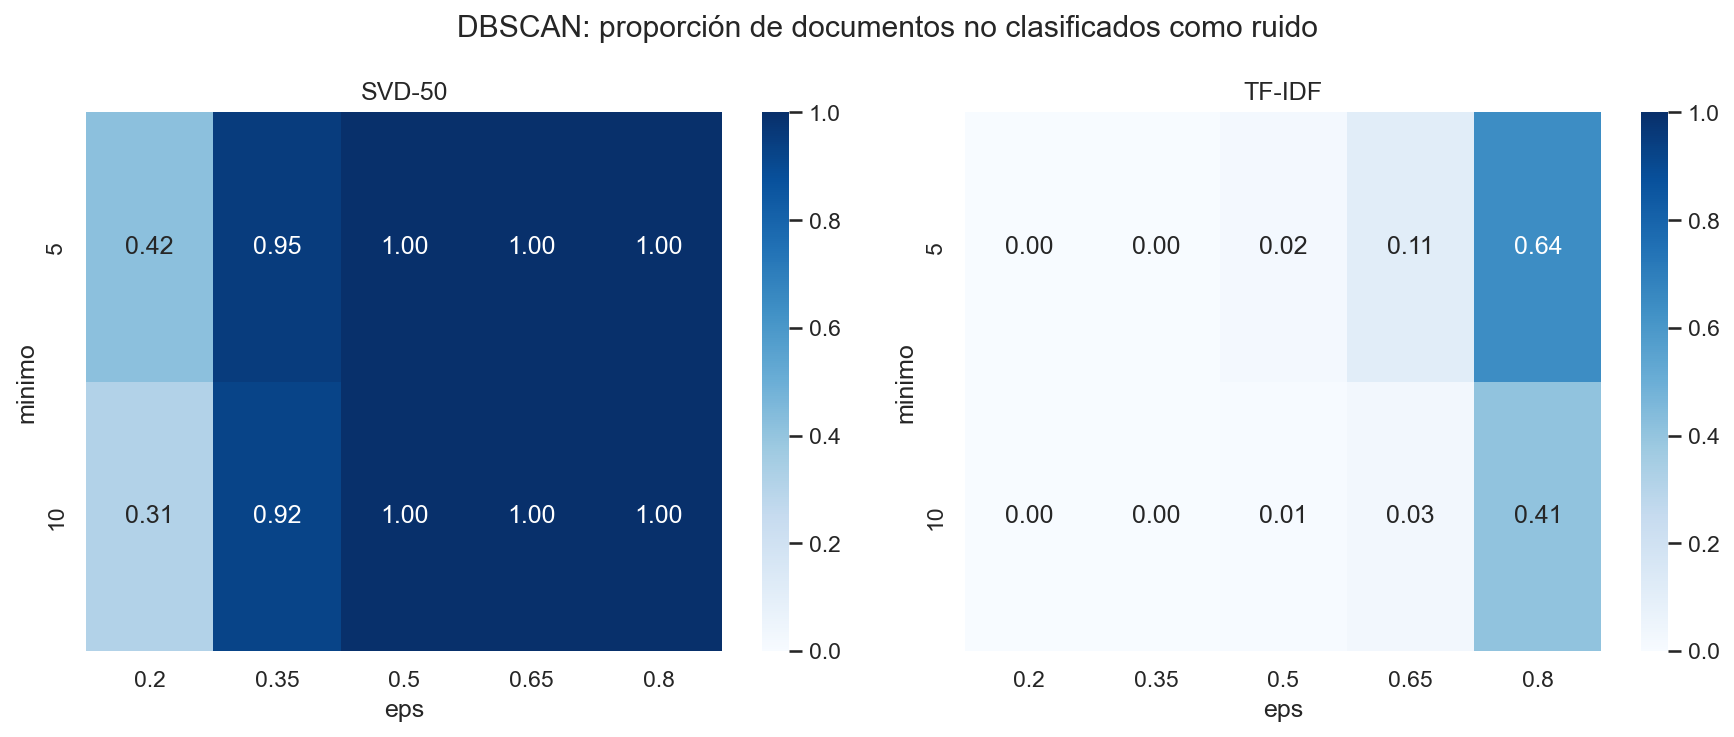

In [17]:
display(Image(filename='resultados/experiment002/08_cobertura_dbscan.png'))

### 2.2. ¿Qué significan los grupos?

Las tablas de mejores configuraciones muestran el efecto de reducir la dimensión por algoritmo. No se compara GMM en el espacio original: una mezcla de alta dimensión resultaría más costosa y los vectores esparsos no satisfacen bien una hipótesis gaussiana. Se interpretan los grupos con términos de mayor TF-IDF promedio y extractos de dos documentos representativos. Los grupos de ruido, si aparecen, no representan necesariamente un tema.

### Tabla: interpretacion

In [18]:
tabla = pd.read_csv(RESULTADOS / 'experiment002' / 'interpretacion.csv')
tabla = tabla[['grupo', 'documentos', 'palabras', 'ejemplo_1']]
display(tabla.round(4))

,grupo,documentos,palabras,ejemplo_1
0,0,199,"car, cars, dealer, engine, speed, price, new, ...",i have had my probe looked at twice by my loca...
1,1,562,"don, think, people, like, msg, say, know, did,...",accounts of anti armenian human right violatio...
2,2,282,"doctor, disease, medical, cancer, pain, treatm...",great post martin very informative well balanc...
3,3,447,"just, good, ve, like, oil, engine, ford, cars,...",howdy i'm a little new to this newsgroup but i...
4,4,460,"game, team, hockey, games, season, players, es...",archive name hockey faq rec sport hockey answe...
5,5,240,"israel, jews, israeli, arab, jewish, arabs, pa...",by elias davidsson april revision oct note you...
6,6,325,"space, orbit, launch, earth, moon, shuttle, lu...",archive name space references last modified da...
7,7,51,"shameful, skepticism, jxp, chastity, surrender...",so just what was it you wanted to say gordon b...
8,8,607,"thanks, graphics, image, mail, program, know, ...",archive name graphics resources list part last...
9,9,127,"armenian, armenians, turkish, genocide, turkey...",pardon me here is to an amherst clown your thr...


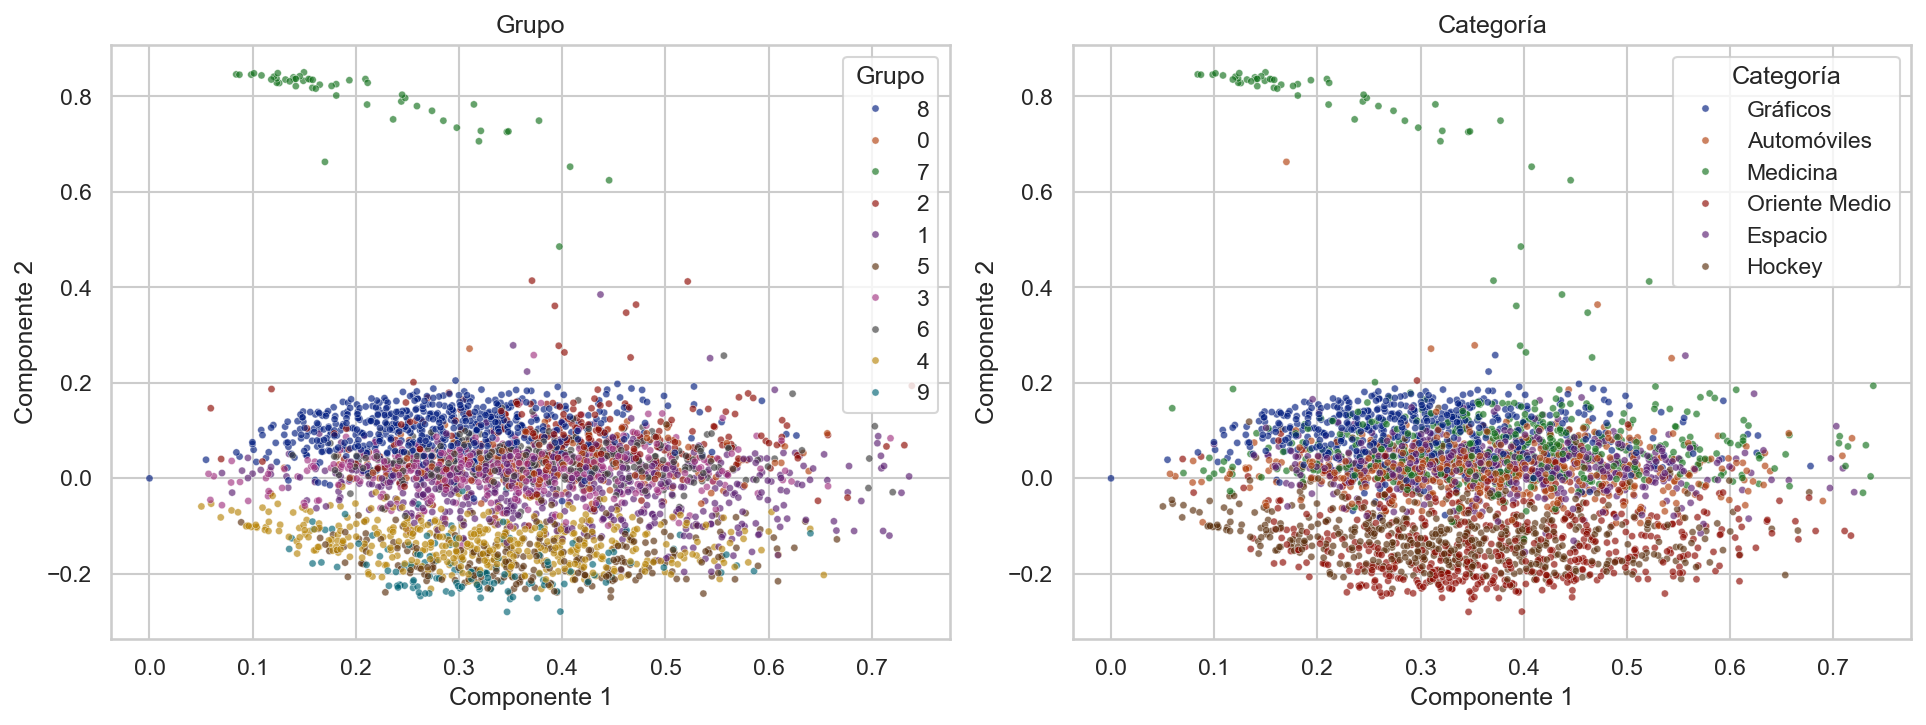

In [19]:
display(Image(filename='resultados/experiment002/05_proyeccion.png'))

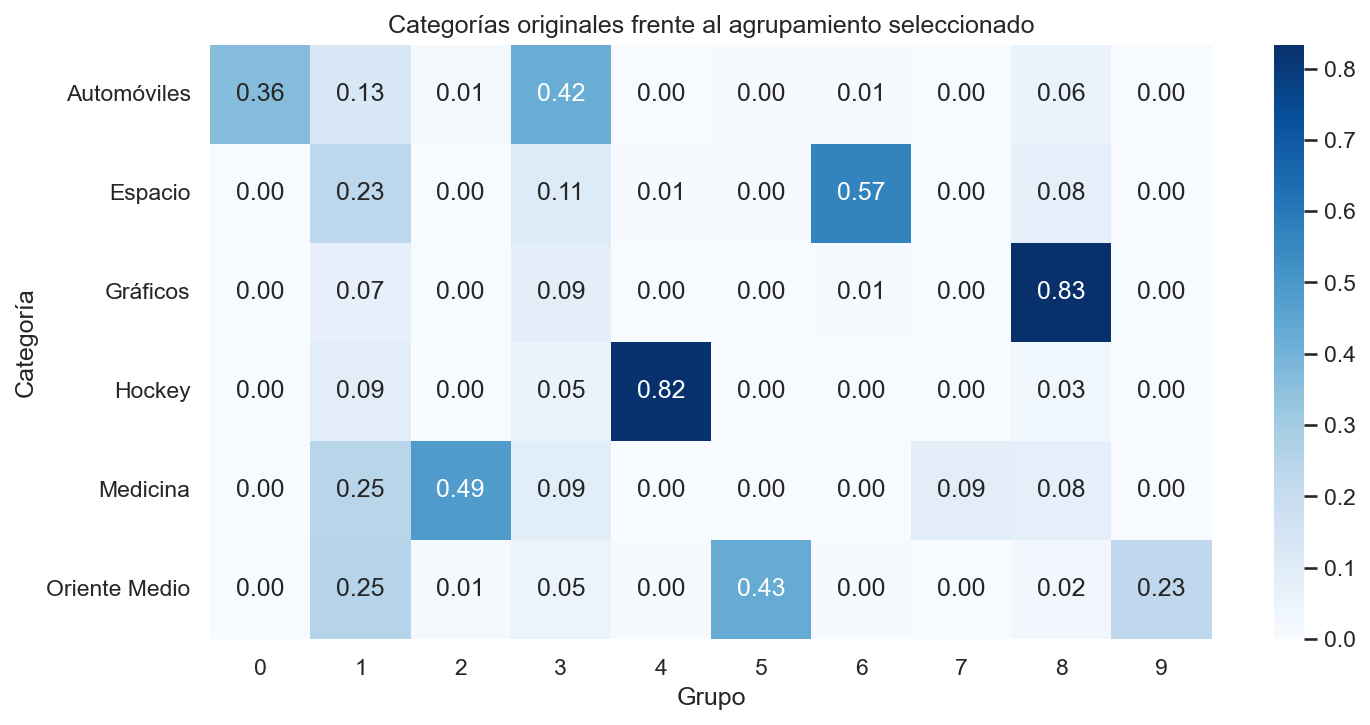

In [20]:
display(Image(filename='resultados/experiment002/06_cruzada.png'))

## 3. Aprendizaje supervisado

### 3.1. Protocolo común y modelos candidatos

Se comparan regresión logística, SGD logístico, árbol de decisión, Random Forest, AdaBoost, Gradient Boosting y SVM con kernel RBF, además de tres ensambles. Las transformaciones se ajustan dentro de Pipeline en cada pliegue. Gradient Boosting usa SVD-50 para limitar su costo. GridSearchCV selecciona por F1 macro en cinco pliegues estratificados comunes, sin acceso a prueba. F1 macro promedia la media armónica de precisión y exhaustividad por clase; las demás métricas se calculan también con promedio macro salvo Accuracy.

Bagging entrena veinte regresiones logísticas sobre remuestras bootstrap de los vectores TF-IDF y promedia probabilidades. La votación dura combina las siete familias con configuraciones preespecificadas. El stacking usa estas mismas siete familias, probabilidades o márgenes fuera de pliegue y XGBoost como metaclasificador (profundidades 2/3, 50/100 árboles). Cada fold externo contiene su propio stacking interno de cinco pliegues; la búsqueda del metaestimador también se limita al entrenamiento externo. La prueba permanece reservada. Las bases de los ensambles se fijan a priori para no reutilizar una selección que vio la validación externa.

### 3.2. ¿Qué modelo generaliza con menor costo?

El mejor individual es SGD (F1 CV=0.9008); el mejor ensamble es Stacking (XGBoost) (F1 CV=0.9001); la diferencia es -0.0007. El menor tiempo total de búsqueda y reajuste corresponde a SGD (0.65 s). Los tiempos son de pared y dependen del hardware y del paralelismo; incluyen diferentes cargas de búsqueda. Se registran por separado ajuste final y predicción.

### Tabla: validacion

In [21]:
tabla = pd.read_csv(RESULTADOS / 'experiment003' / 'validacion.csv')
tabla = tabla[['modelo', 'F1_CV', 'DE_CV', 'segundos', 'segundos_refit']]
display(tabla.round(4))

,modelo,F1_CV,DE_CV,segundos,segundos_refit
0,SGD,0.9008,0.0078,0.6490,0.1443
1,Stacking (XGBoost),0.9001,0.0068,216.1715,111.0298
2,Regresión logística,0.8984,0.0070,1.1697,0.2179
3,SVM RBF,0.8964,0.0074,6.0373,2.2060
4,Bagging (regresión logística),0.8963,0.0105,6.4283,2.2418
5,Votación (7 modelos),0.8923,0.0075,43.7274,21.1050
6,Gradient Boosting,0.8451,0.0105,17.4166,5.4855
7,Random Forest,0.8322,0.0119,6.2374,1.3517
8,Árbol de decisión,0.6994,0.0061,1.4161,0.4618
9,AdaBoost,0.6563,0.0216,4.5181,1.7667


### Tabla: mejora ensambles

In [22]:
tabla = pd.read_csv(RESULTADOS / 'experiment003' / 'mejora_ensambles.csv')
display(tabla.round(4))

,modelo,delta_CV,delta_prueba
0,Stacking (XGBoost),-0.0007,-0.0153
1,Bagging (regresión logística),-0.0044,0.0012
2,Votación (7 modelos),-0.0084,-0.0027


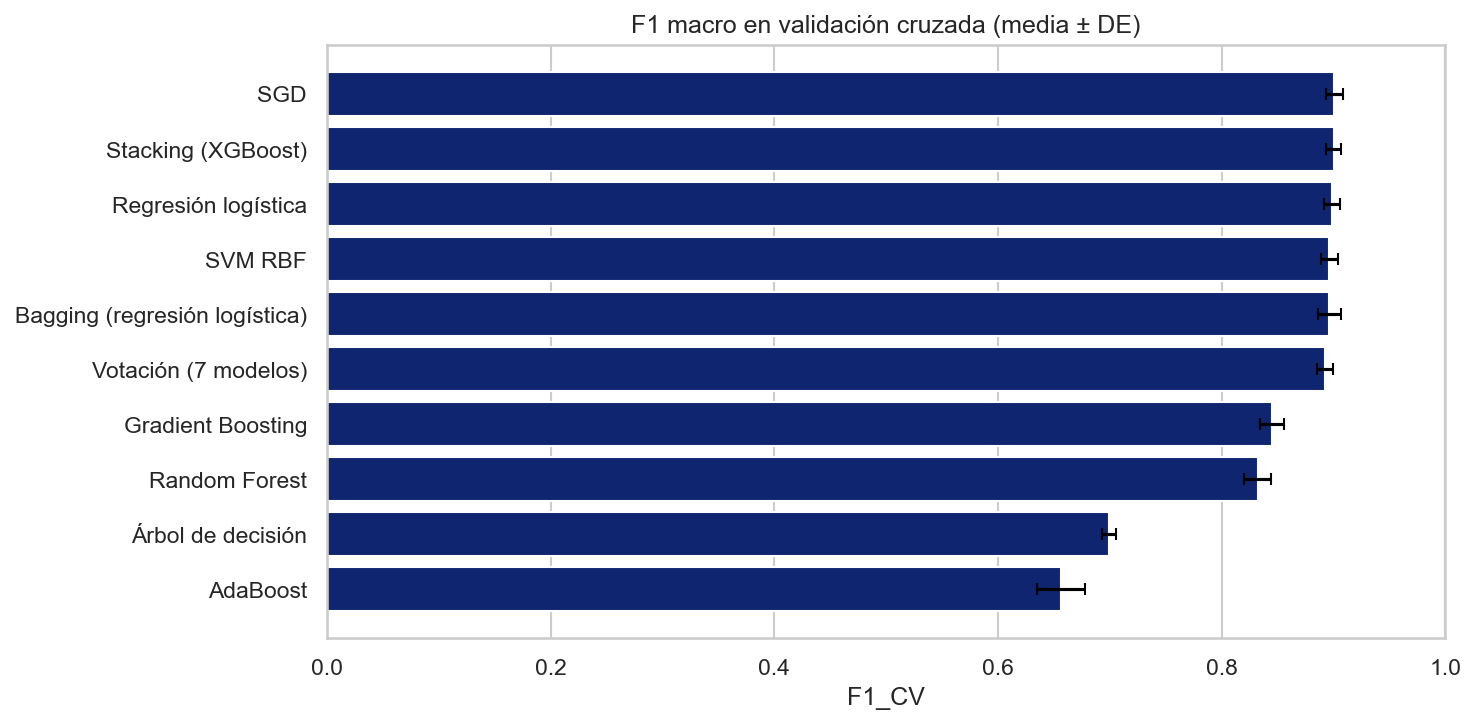

In [23]:
display(Image(filename='resultados/experiment003/01_validacion.png'))

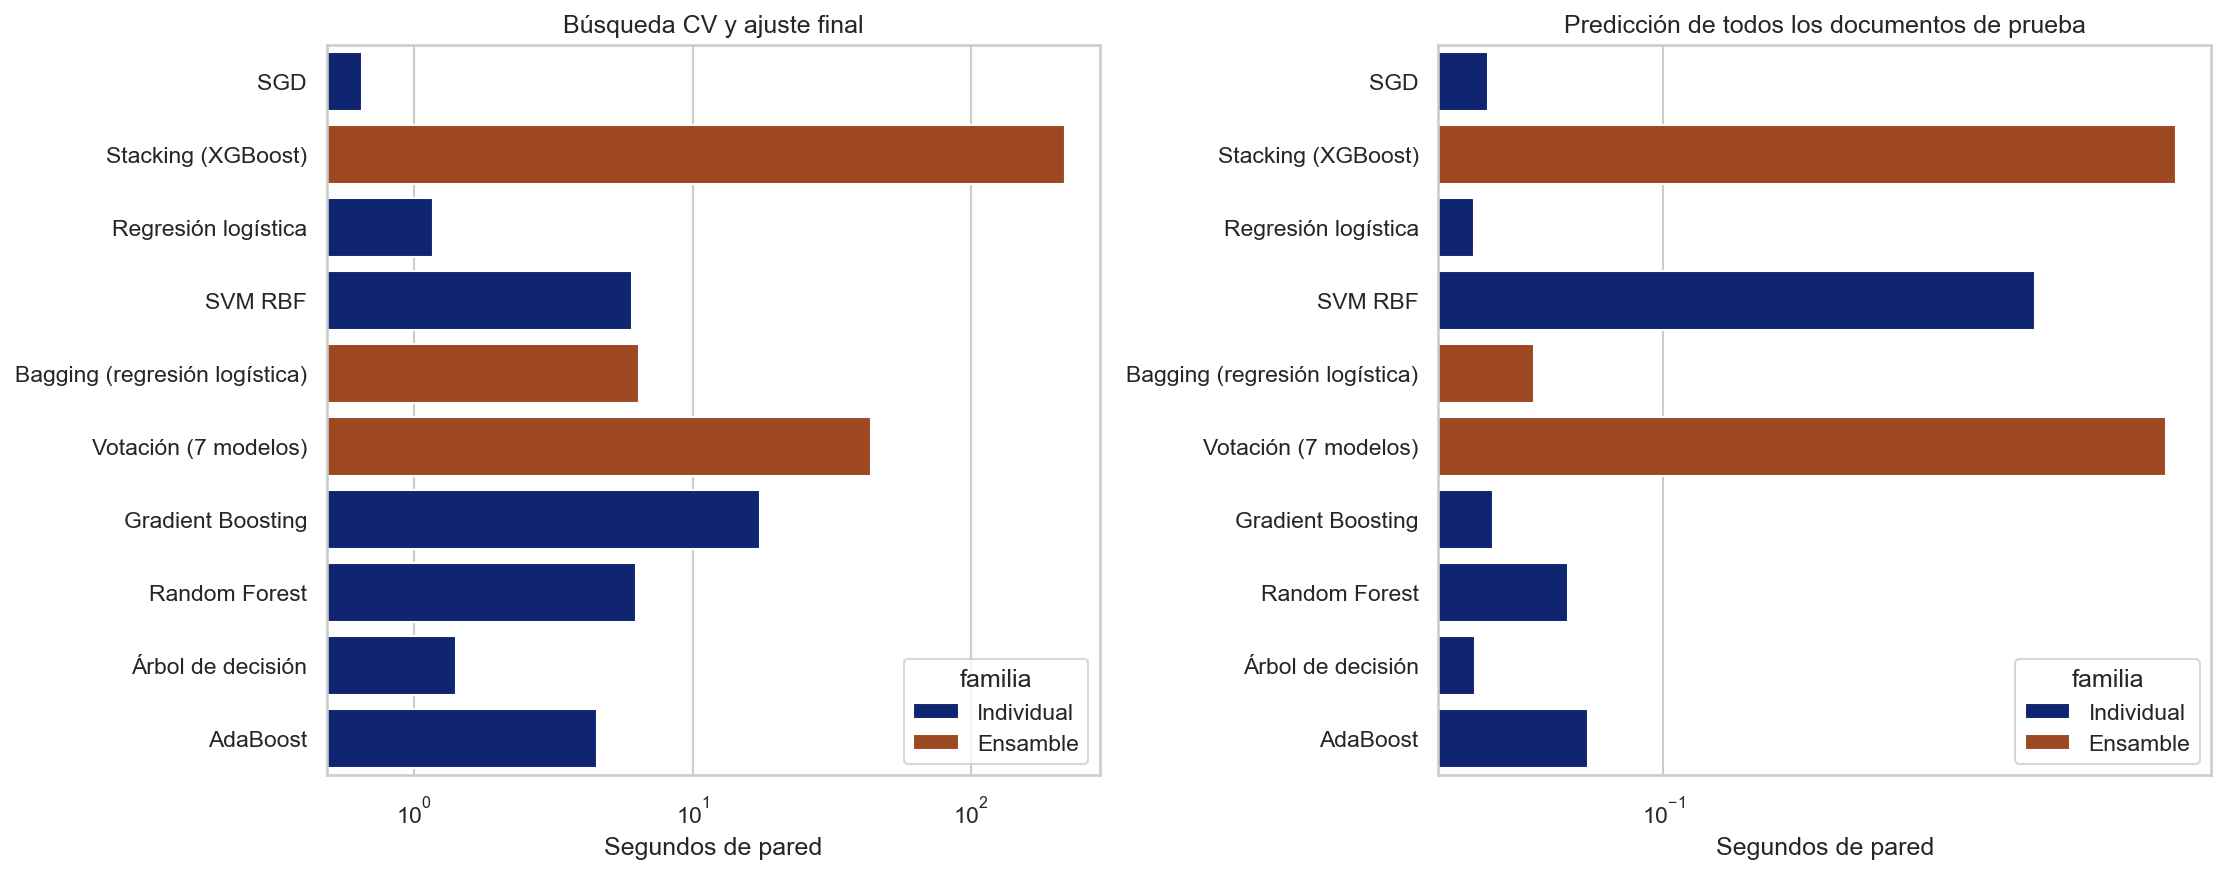

In [24]:
display(Image(filename='resultados/experiment003/06_tiempos.png'))

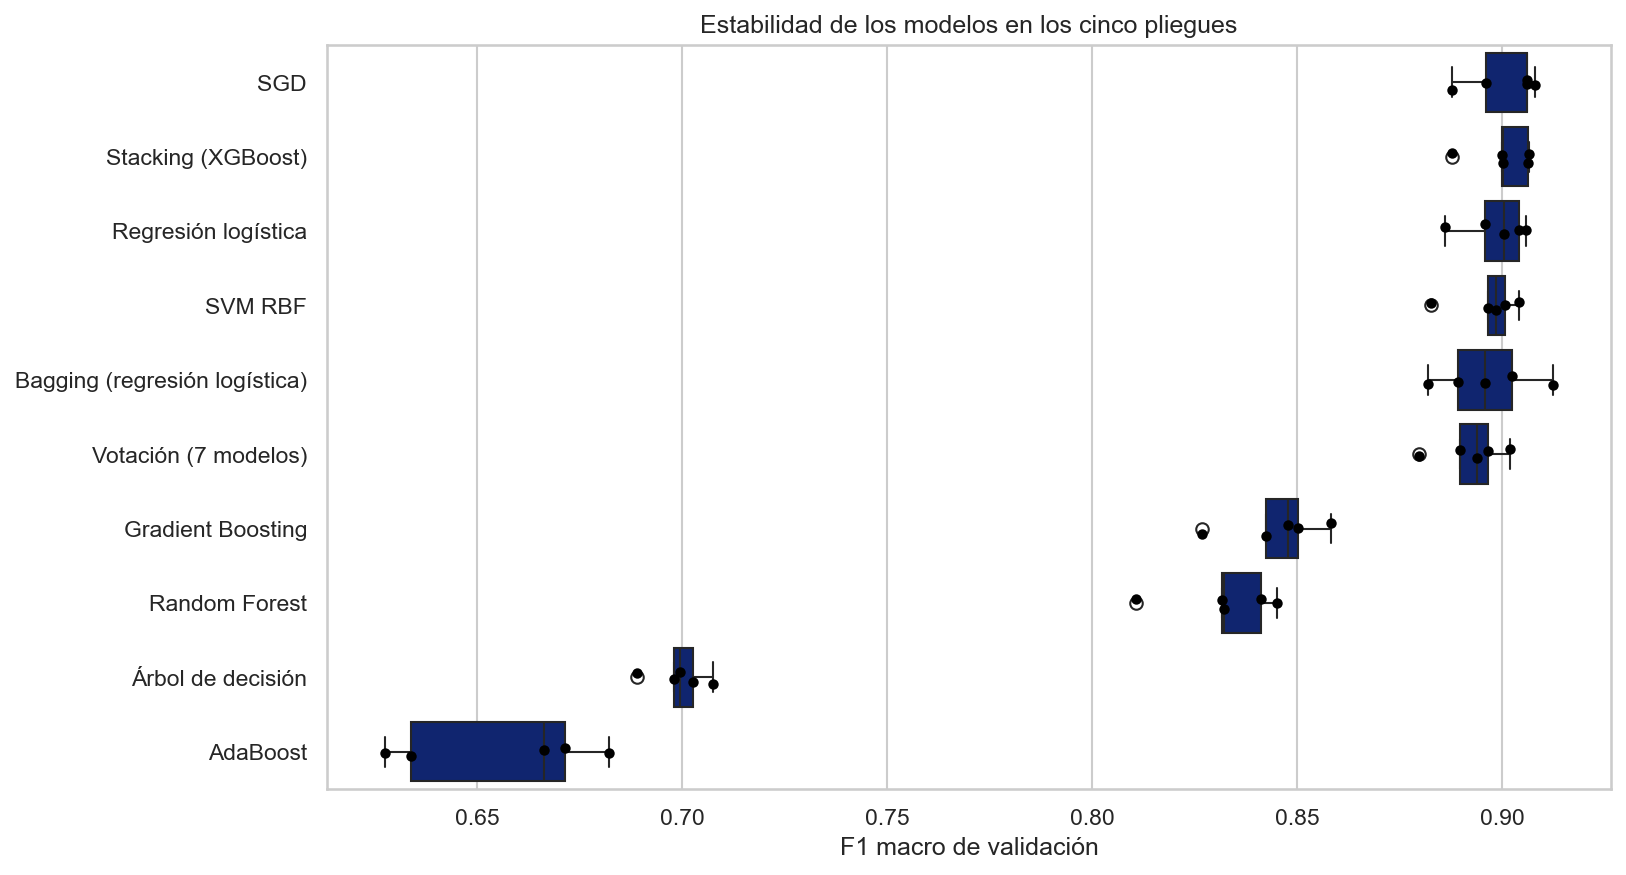

In [25]:
display(Image(filename='resultados/experiment003/07_estabilidad_cv.png'))

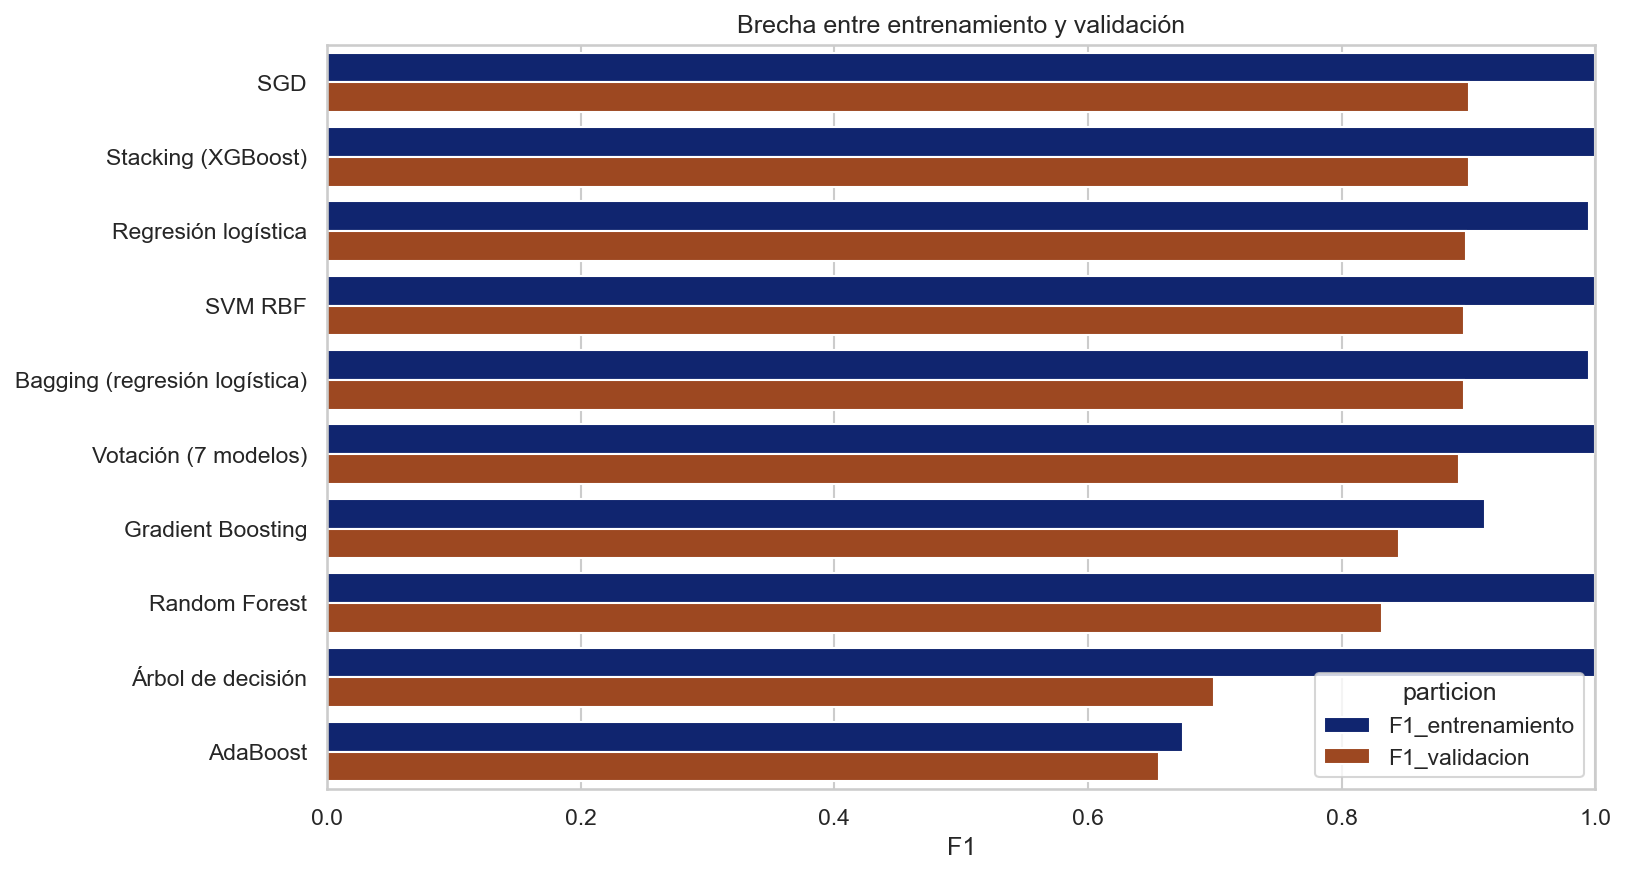

In [26]:
display(Image(filename='resultados/experiment003/08_brecha_cv.png'))

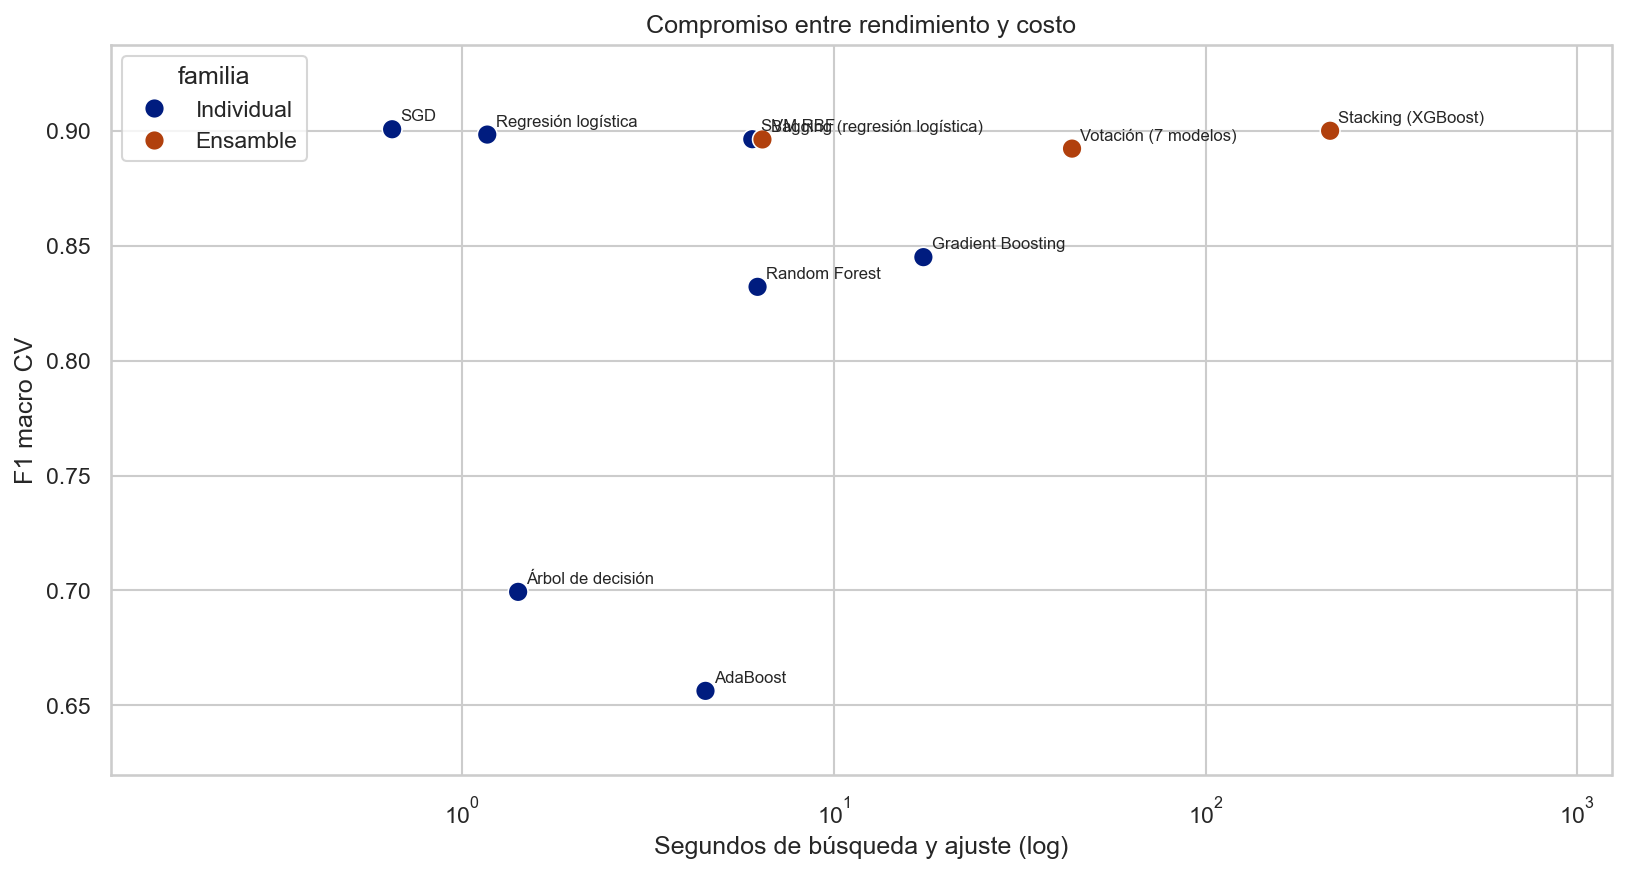

In [27]:
display(Image(filename='resultados/experiment003/09_costo_rendimiento.png'))

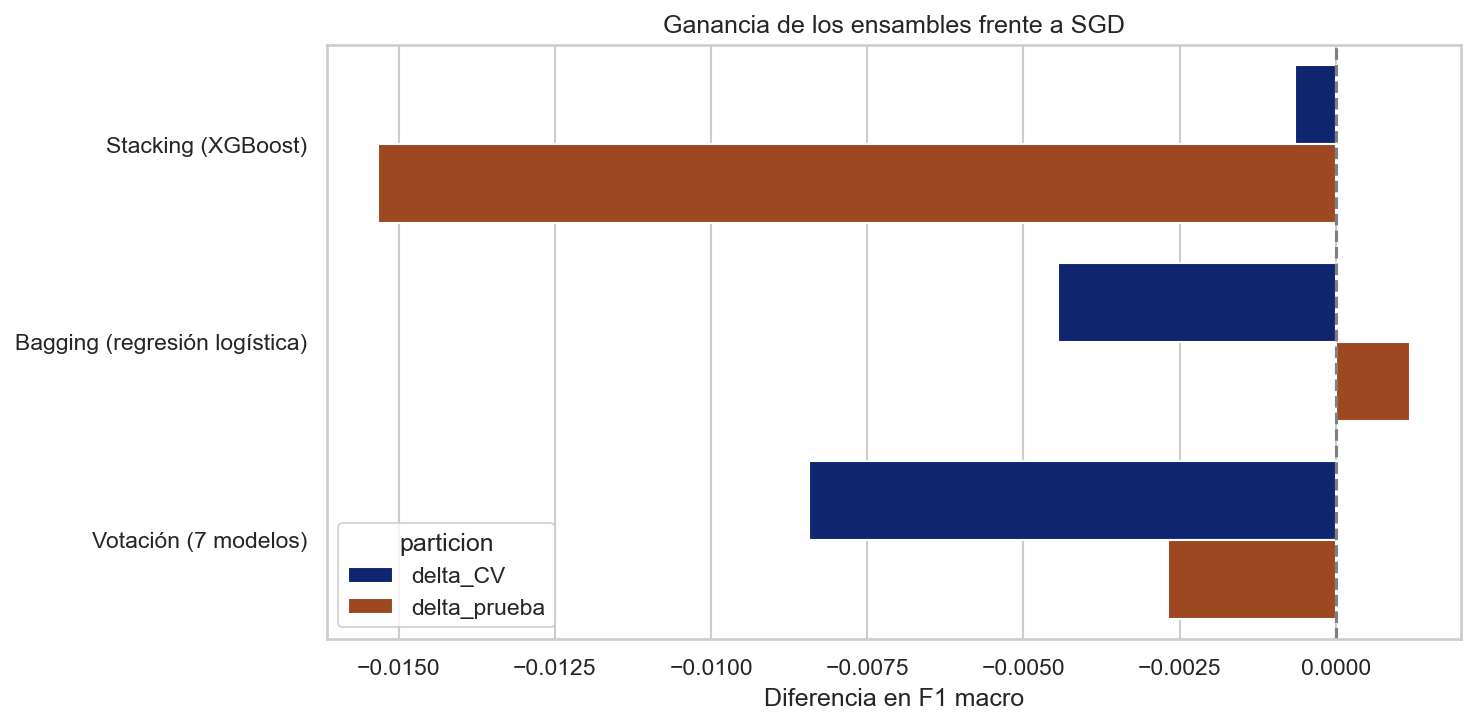

In [28]:
display(Image(filename='resultados/experiment003/13_mejora_ensambles.png'))

### 3.3. Evaluación y errores en prueba

El modelo seleccionado por CV es SGD, con F1 macro 0.9008 (DE entre pliegues 0.0078); obtiene Accuracy 0.8989, Precision 0.9007, Recall 0.8989 y F1 macro 0.8991 en prueba. Su diferencia prueba − CV es -0.0017. La mayor confusión fuera de la diagonal es Espacio → Automóviles (9 casos); revisar extractos permite distinguir solapamiento léxico, ambigüedad y documentos cortos.

### Tabla: metricas prueba

In [29]:
tabla = pd.read_csv(RESULTADOS / 'experiment003' / 'metricas_prueba.csv')
display(tabla.round(4))

,modelo,Accuracy,Precision,Recall,F1,segundos_prediccion
0,SGD,0.8989,0.9007,0.8989,0.8991,0.0486
1,Stacking (XGBoost),0.8833,0.8860,0.8833,0.8838,0.8237
2,Regresión logística,0.8956,0.8982,0.8956,0.8959,0.0458
3,SVM RBF,0.8911,0.8967,0.8911,0.8922,0.4605
4,Bagging (regresión logística),0.9000,0.9028,0.9000,0.9003,0.0589
5,Votación (7 modelos),0.8956,0.8993,0.8956,0.8964,0.7888
6,Gradient Boosting,0.8589,0.8588,0.8589,0.8584,0.0496
7,Random Forest,0.8389,0.8455,0.8389,0.8386,0.0677
8,Árbol de decisión,0.6944,0.7065,0.6944,0.6955,0.0461
9,AdaBoost,0.6289,0.8139,0.6289,0.6568,0.0735


### Tabla: errores por par

In [30]:
tabla = pd.read_csv(RESULTADOS / 'experiment003' / 'errores_por_par.csv')
tabla = tabla[['real', 'predicha', 'errores']]
tabla = tabla.head(5)
display(tabla.round(4))

,real,predicha,errores
0,Espacio,Automóviles,9
1,Gráficos,Automóviles,8
2,Gráficos,Espacio,8
3,Medicina,Automóviles,7
4,Espacio,Gráficos,6


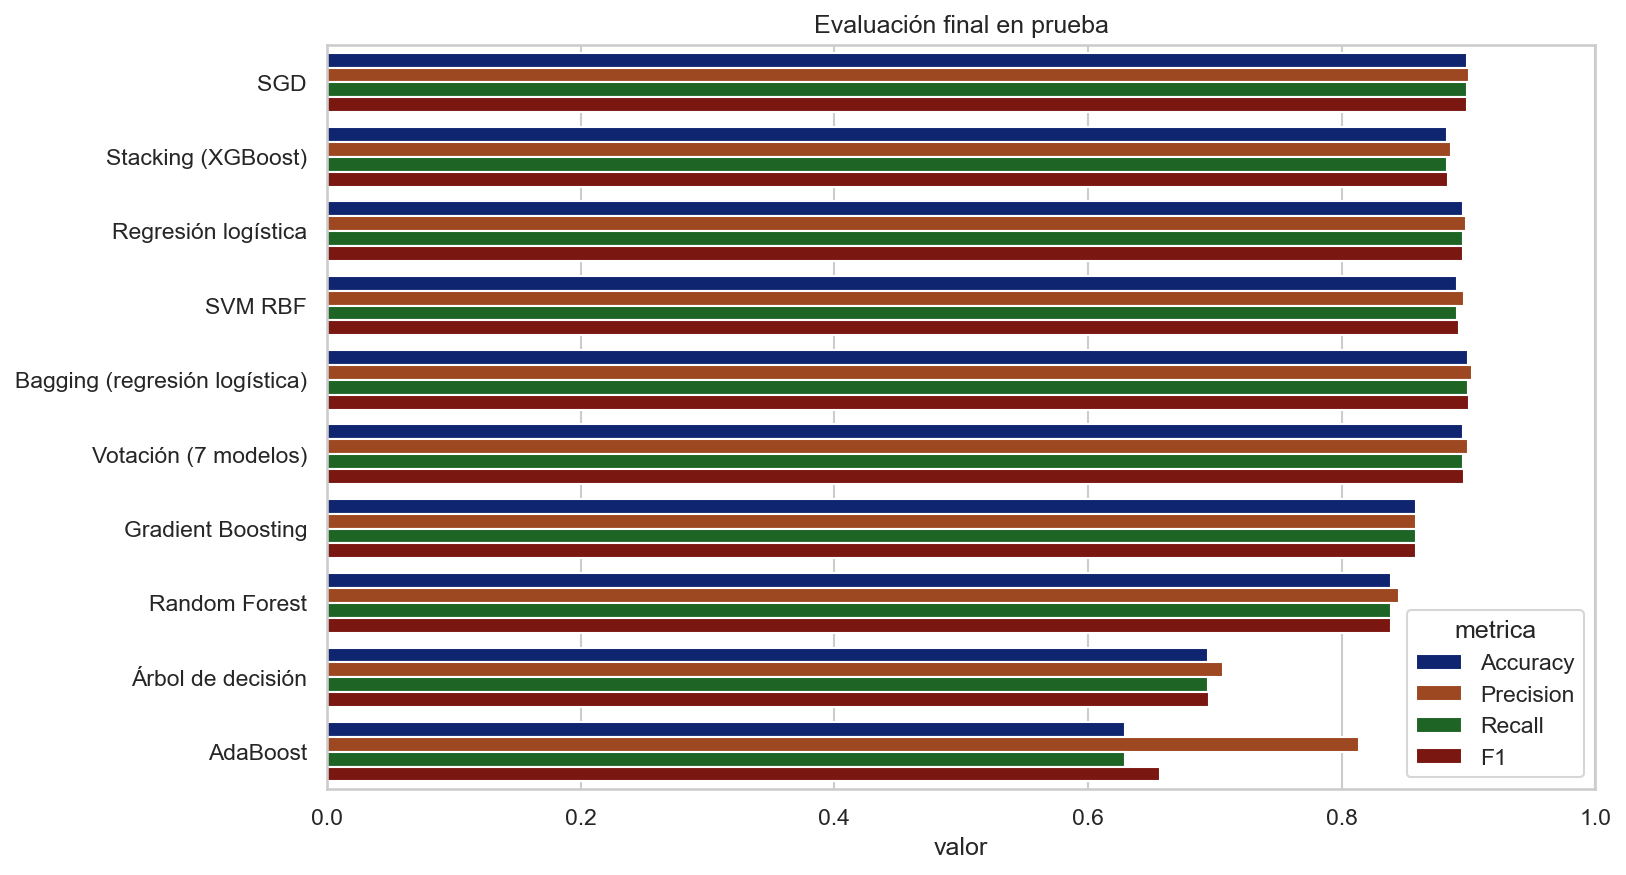

In [31]:
display(Image(filename='resultados/experiment003/02_metricas.png'))

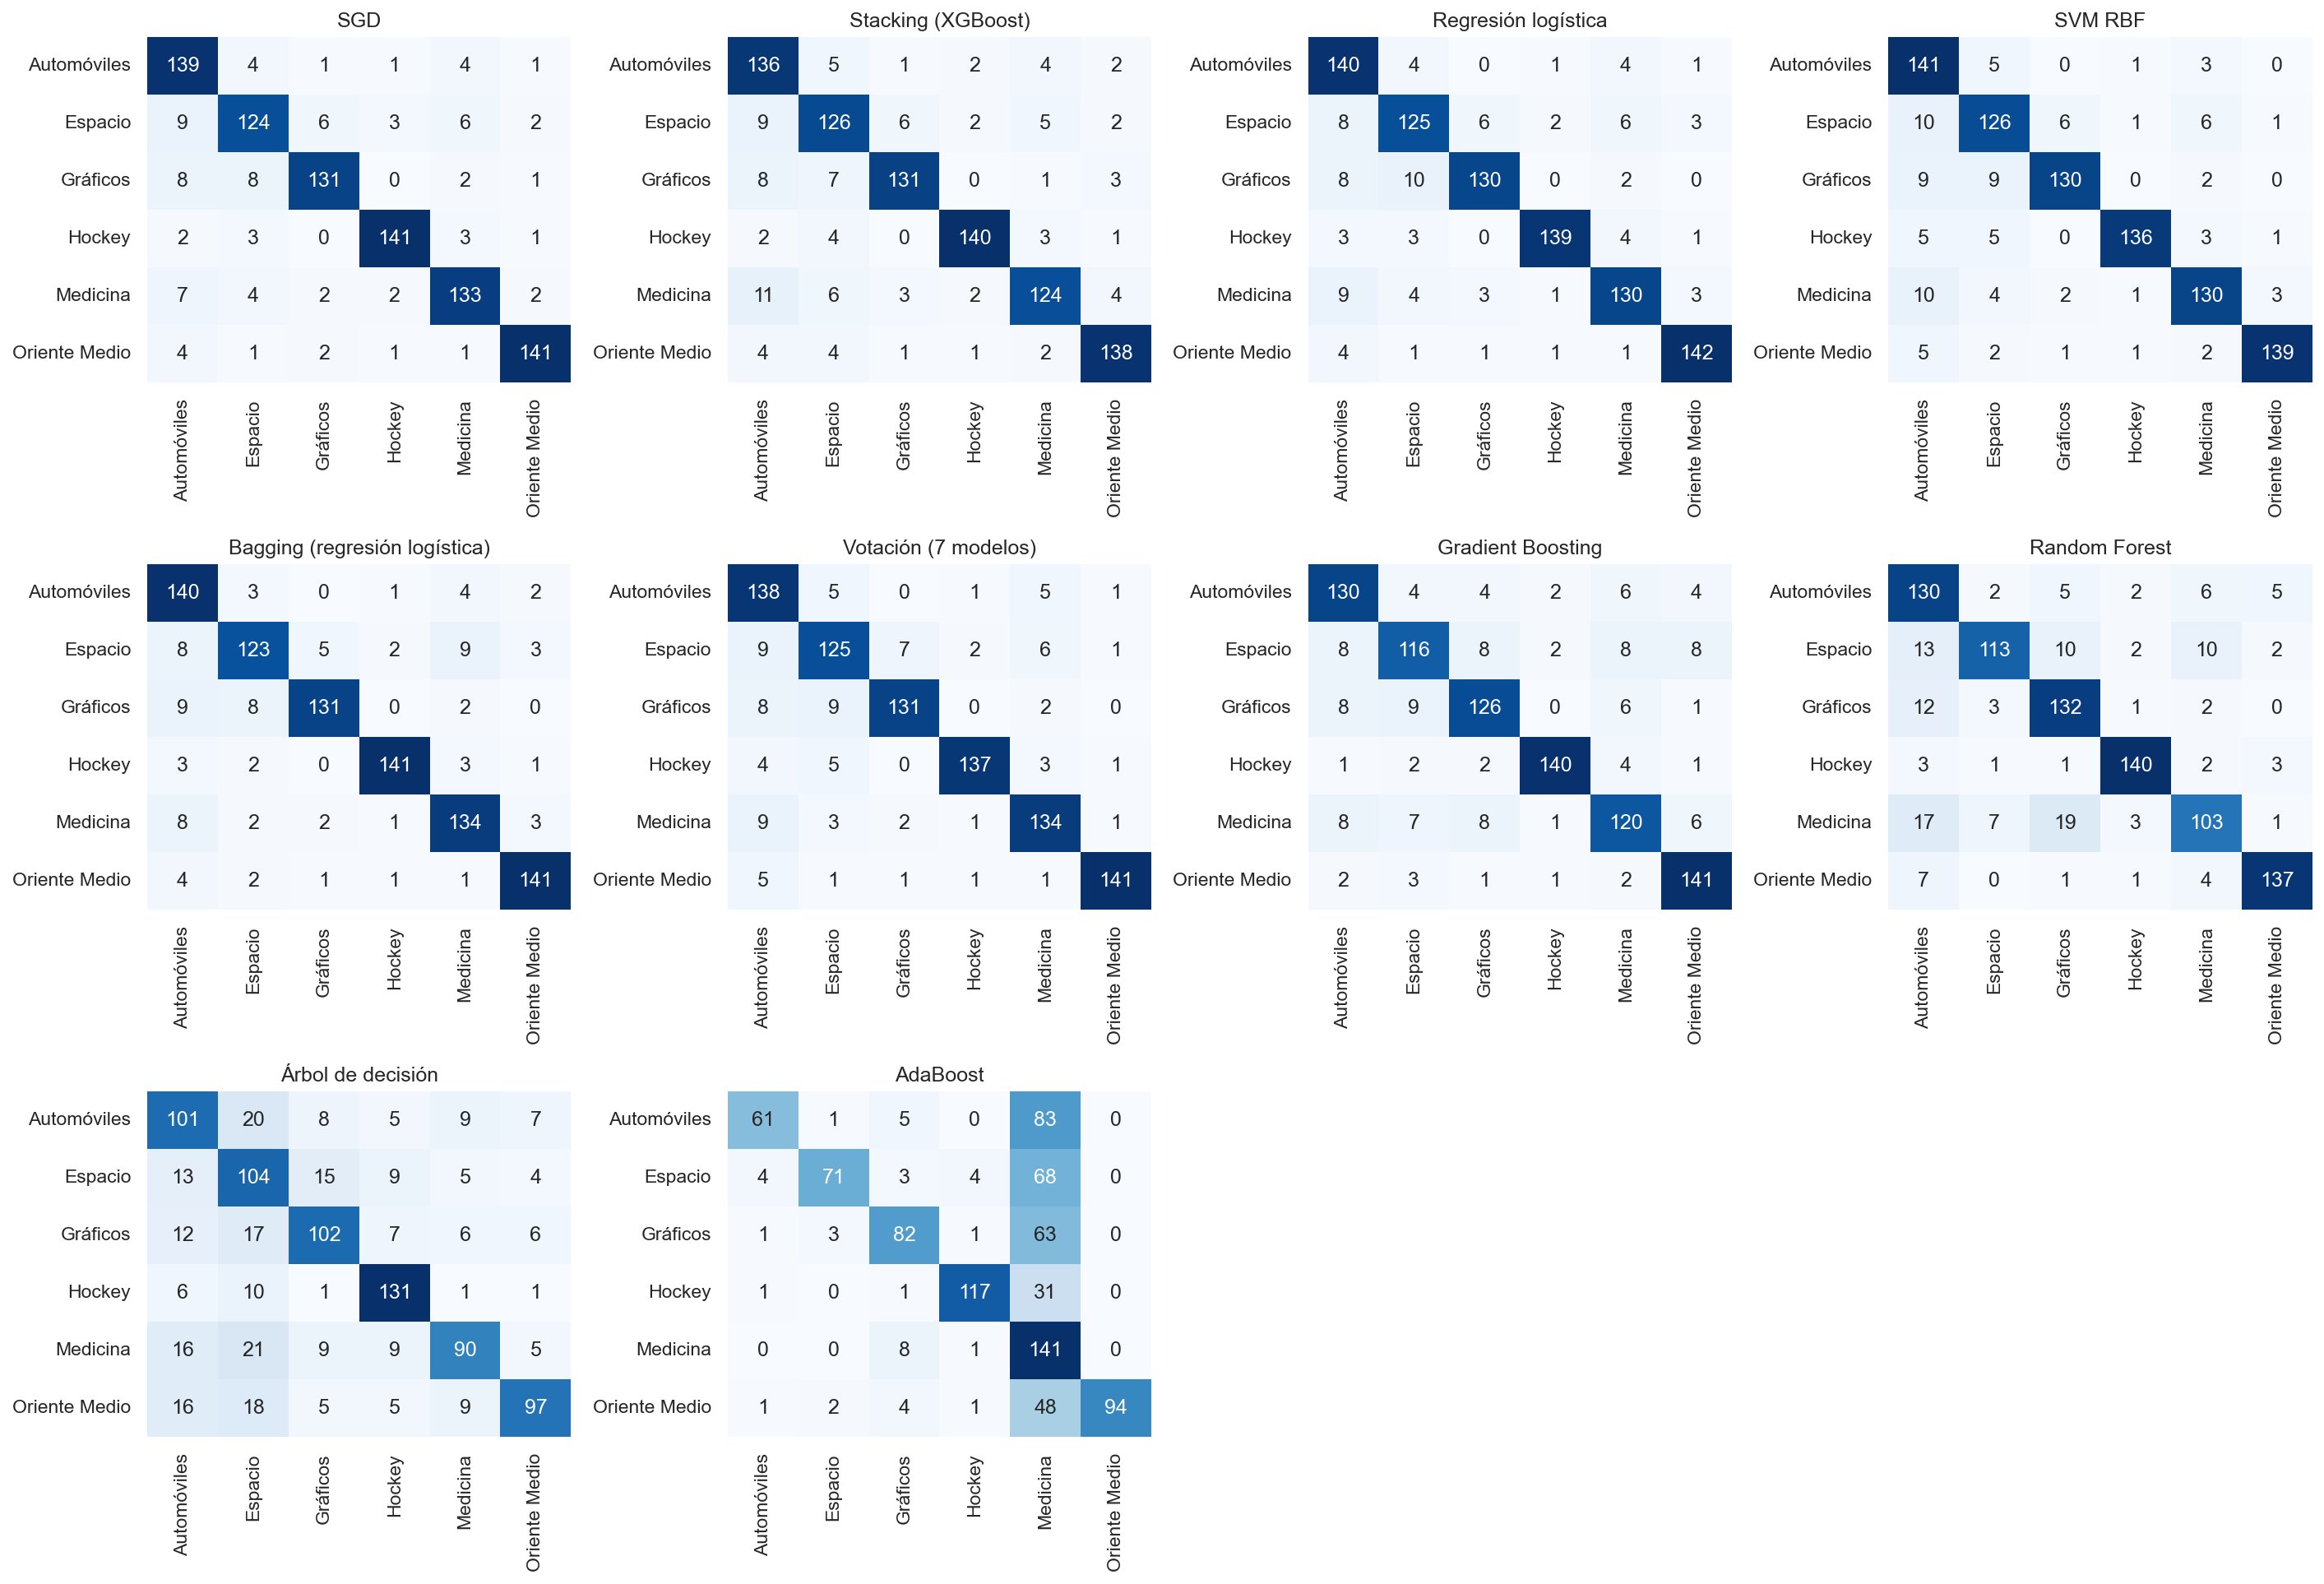

In [32]:
display(Image(filename='resultados/experiment003/03_confusiones.png'))

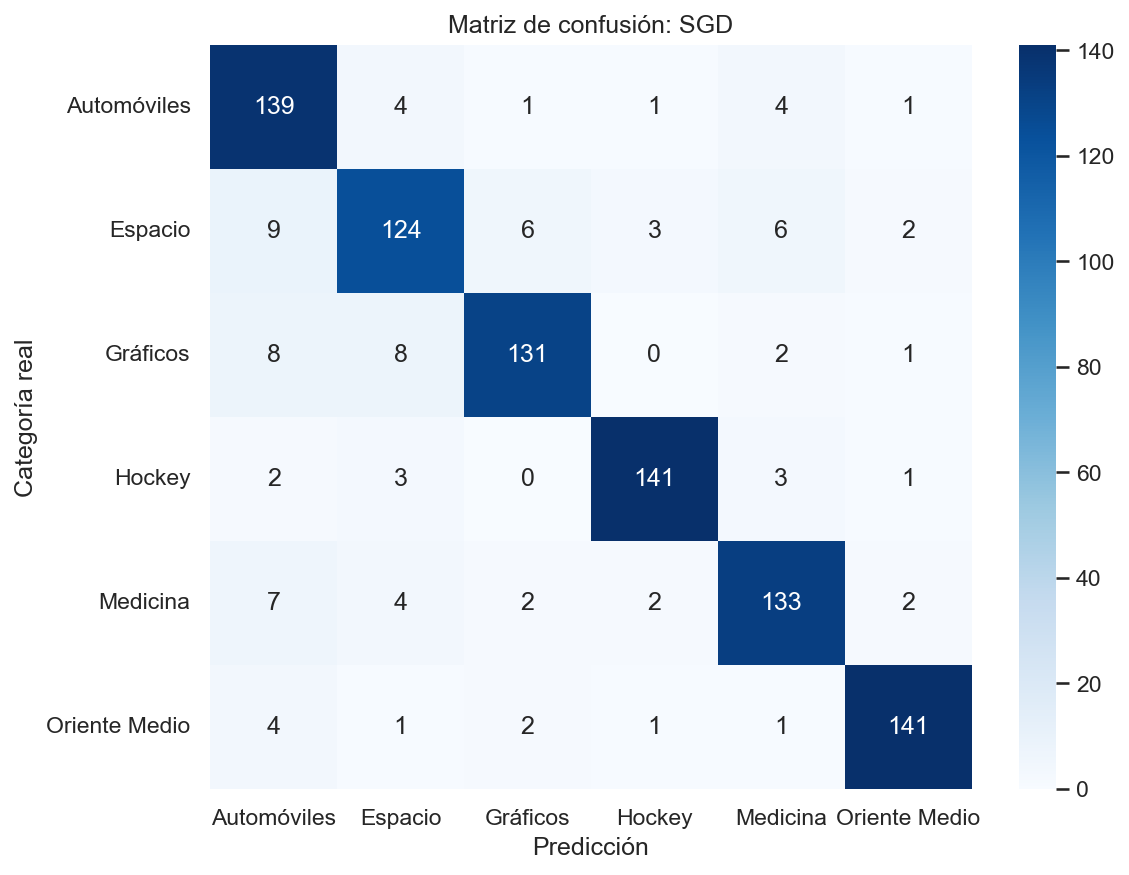

In [33]:
display(Image(filename='resultados/experiment003/04_mejor_confusion.png'))

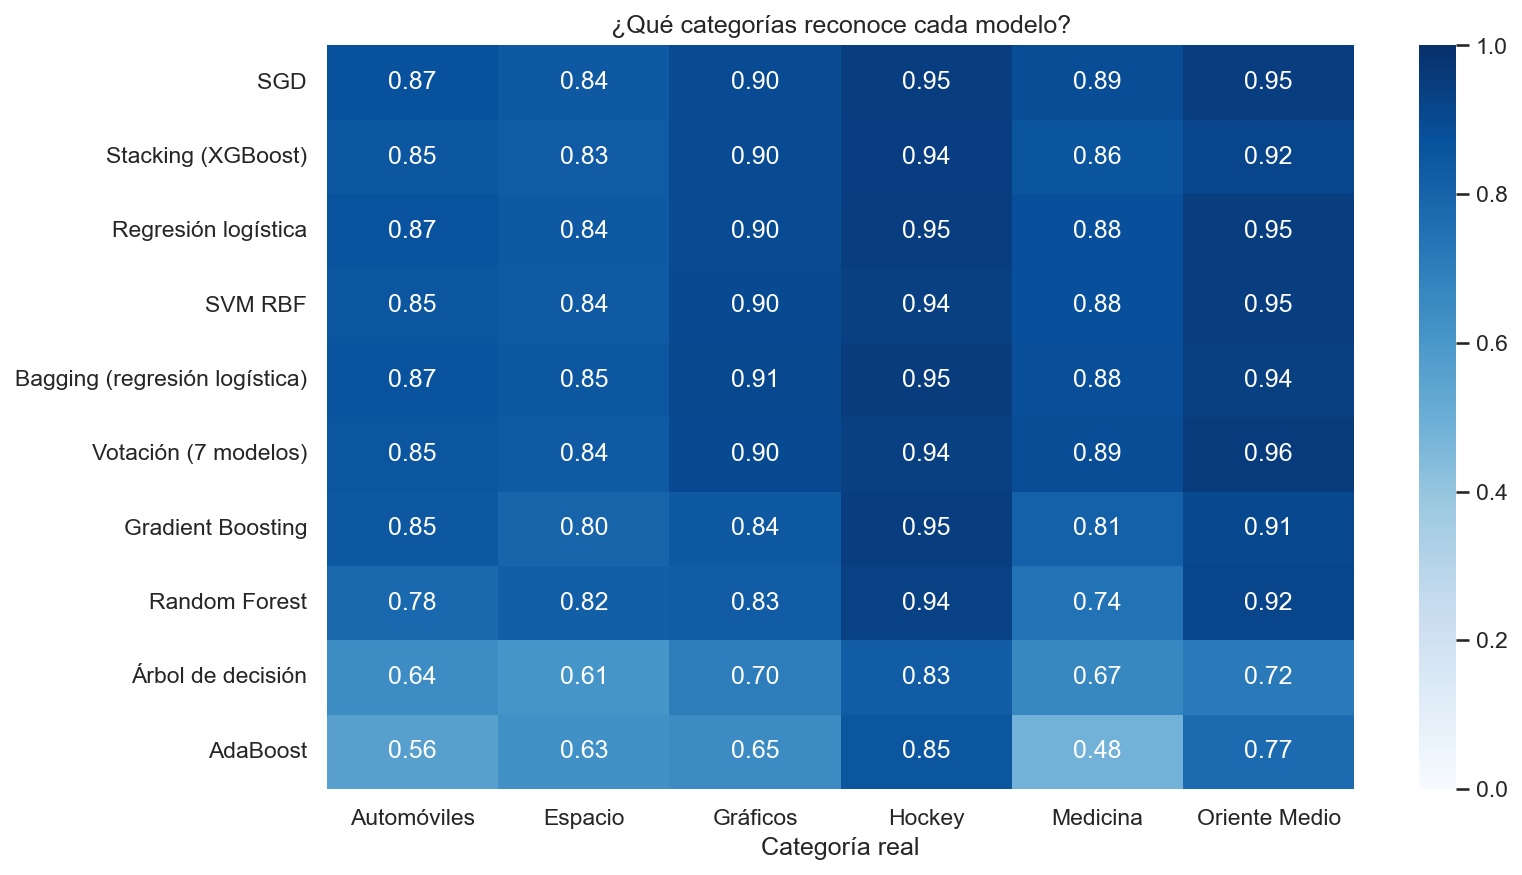

In [34]:
display(Image(filename='resultados/experiment003/10_f1_por_clase.png'))

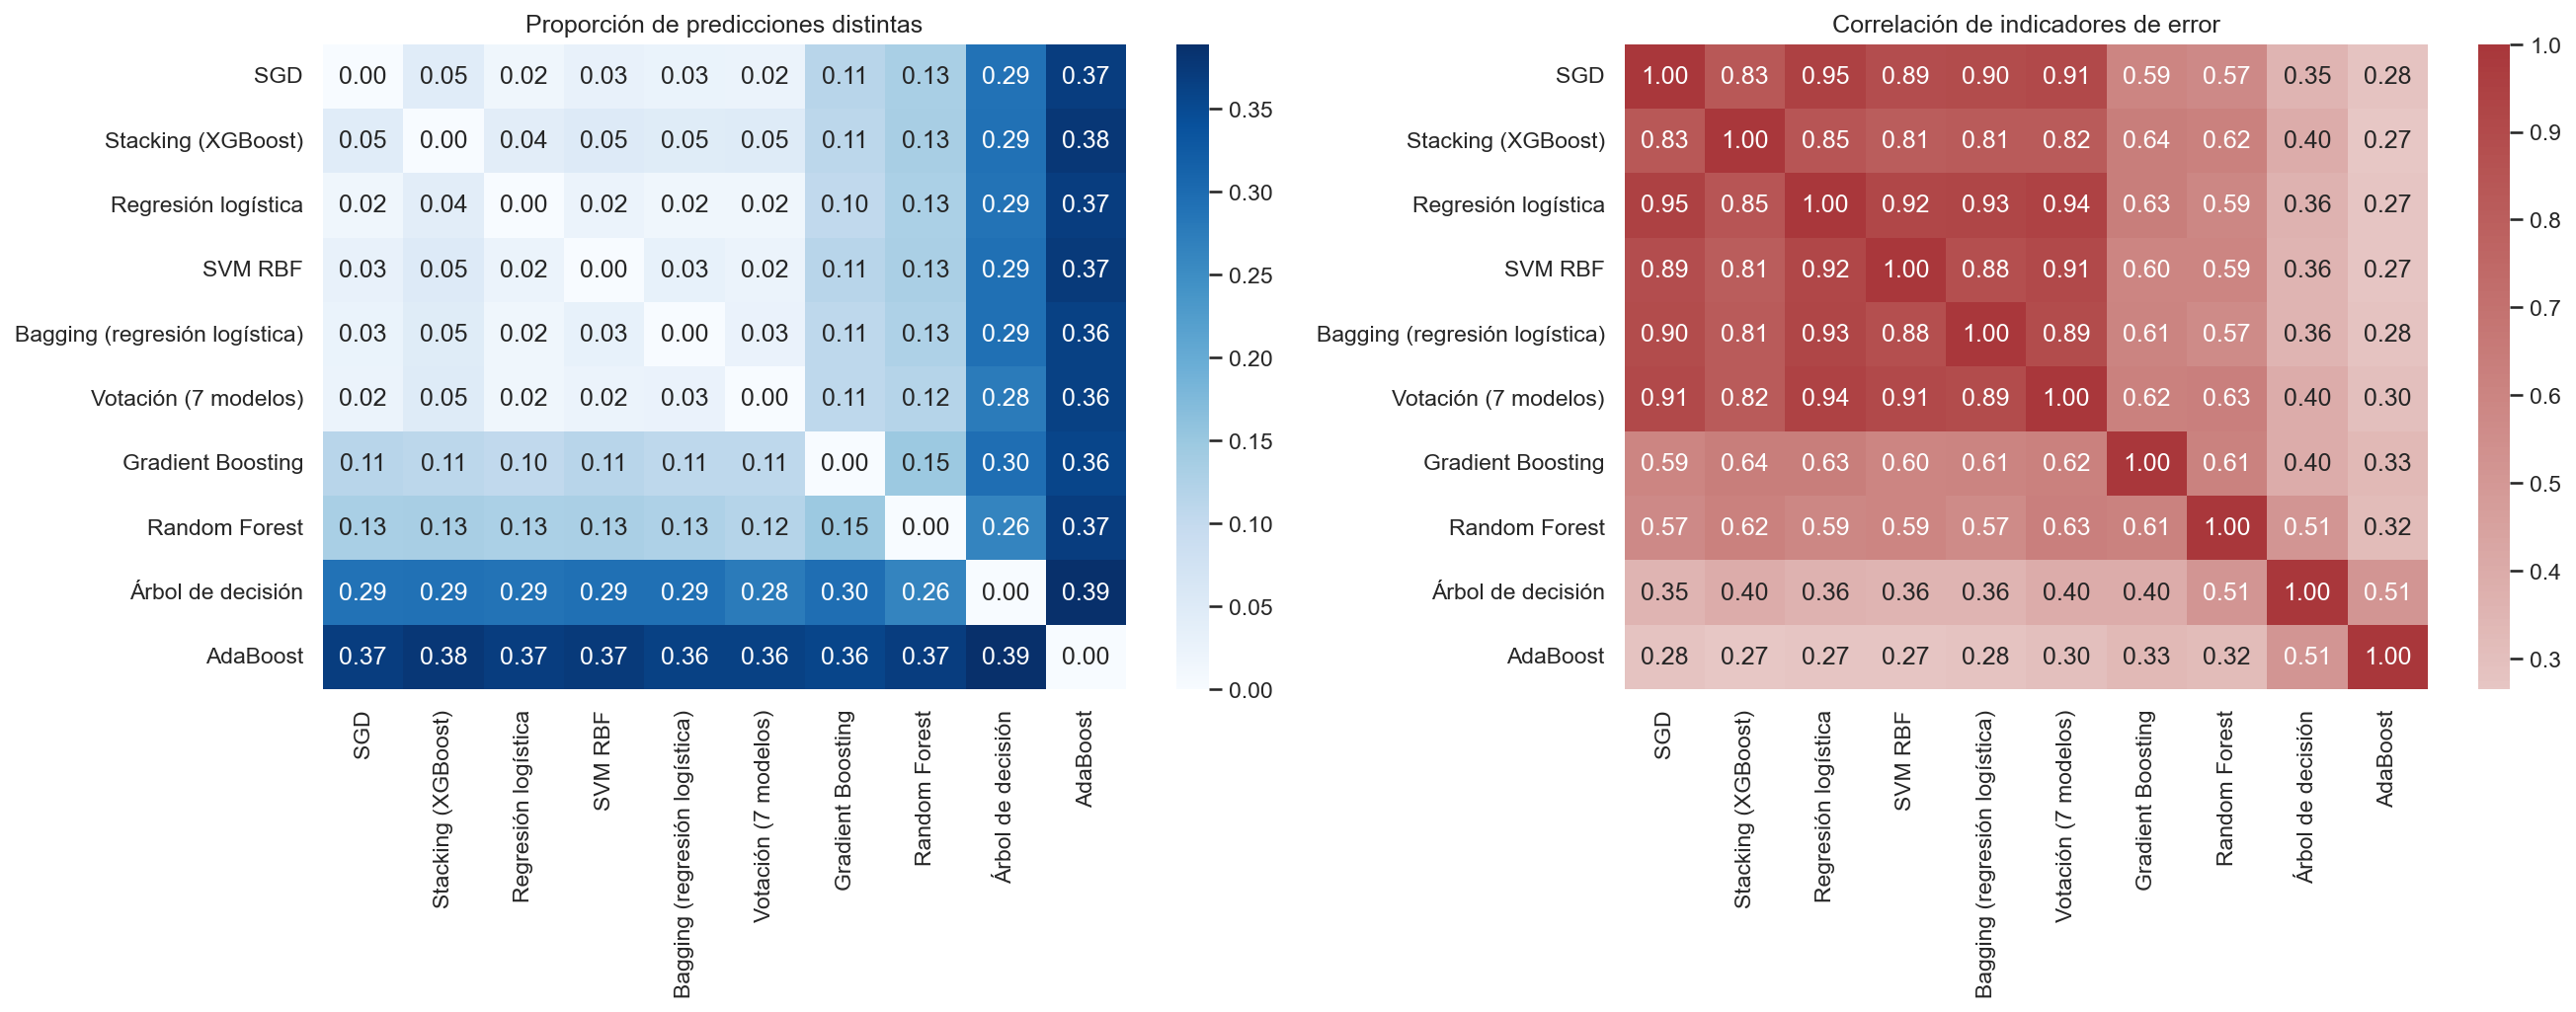

In [35]:
display(Image(filename='resultados/experiment003/11_diversidad.png'))

### 3.4. ¿Son distinguibles los finalistas?

Los tres primeros de CV (SGD, Stacking (XGBoost), Regresión logística) se comparan con 2,000 réplicas bootstrap pareadas y estratificadas por etiqueta real. Se calculan diferencias de F1, intervalos percentiles marginales al 95% y p bilaterales aproximados mediante la distribución centrada bajo H0. Holm controla la familia de tres contrastes al 5%; se rechazan 1 de tres. Los IC marginales no son intervalos simultáneos ajustados; no rechazar no demuestra equivalencia. La inferencia está condicionada a los modelos entrenados y al muestreo de prueba.

### Tabla: bootstrap holm

In [36]:
tabla = pd.read_csv(RESULTADOS / 'experiment003' / 'bootstrap_holm.csv')
tabla = tabla[['modelo_A', 'modelo_B', 'delta_F1', 'IC_inferior', 'IC_superior', 'p_Holm']]
display(tabla.round(4))

,modelo_A,modelo_B,delta_F1,IC_inferior,IC_superior,p_Holm
0,SGD,Stacking (XGBoost),0.0153,0.0047,0.0277,0.0345
1,SGD,Regresión logística,0.0032,-0.0033,0.0099,0.3578
2,Stacking (XGBoost),Regresión logística,-0.0122,-0.0238,-0.0017,0.0650


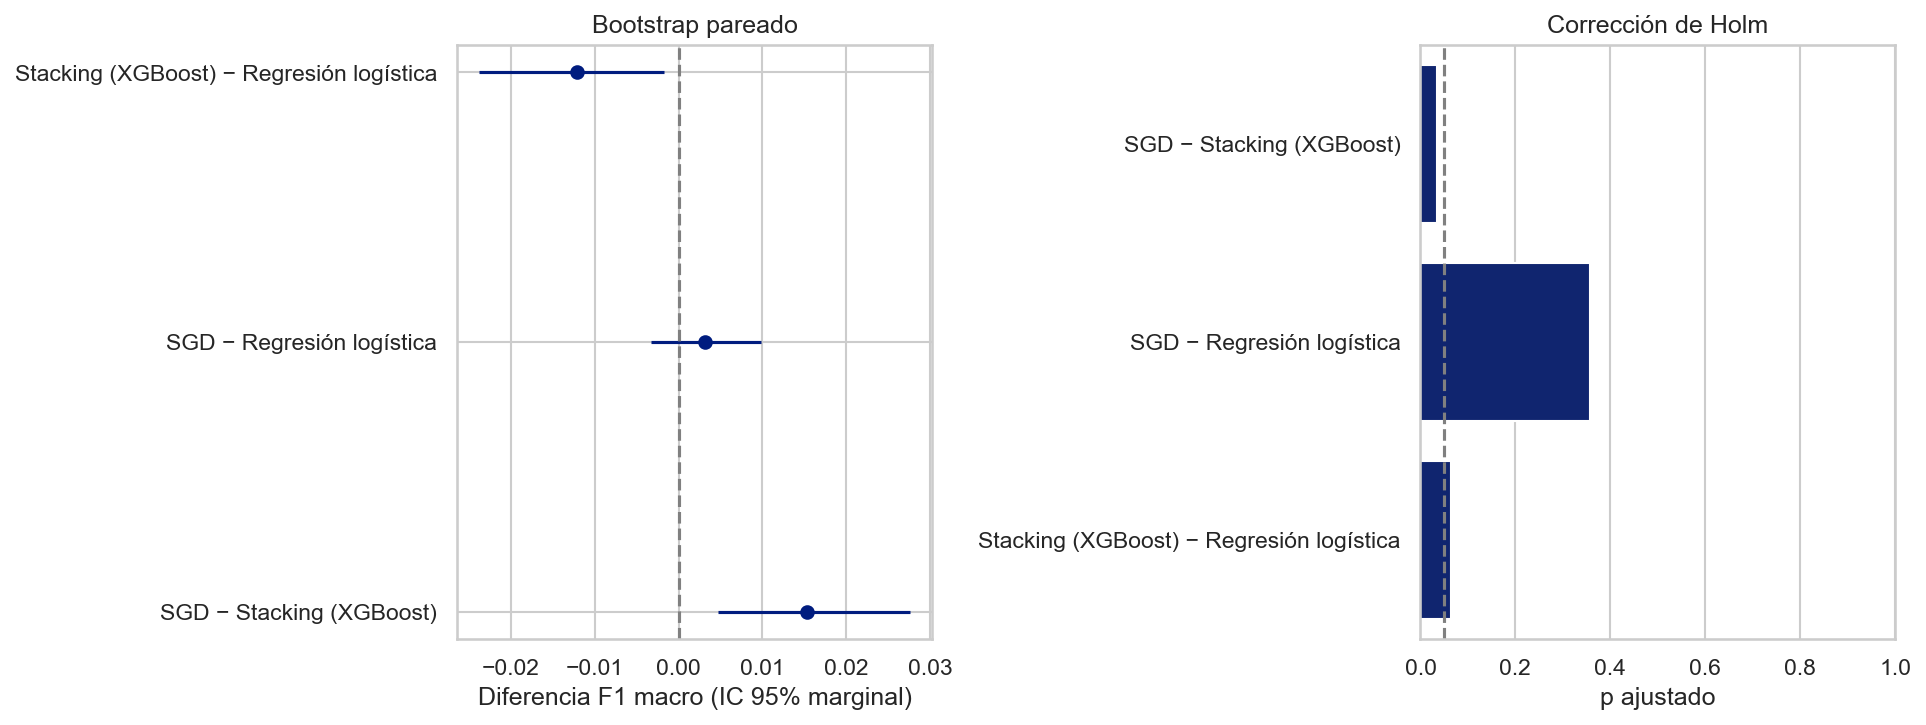

In [37]:
display(Image(filename='resultados/experiment003/05_bootstrap_holm.png'))

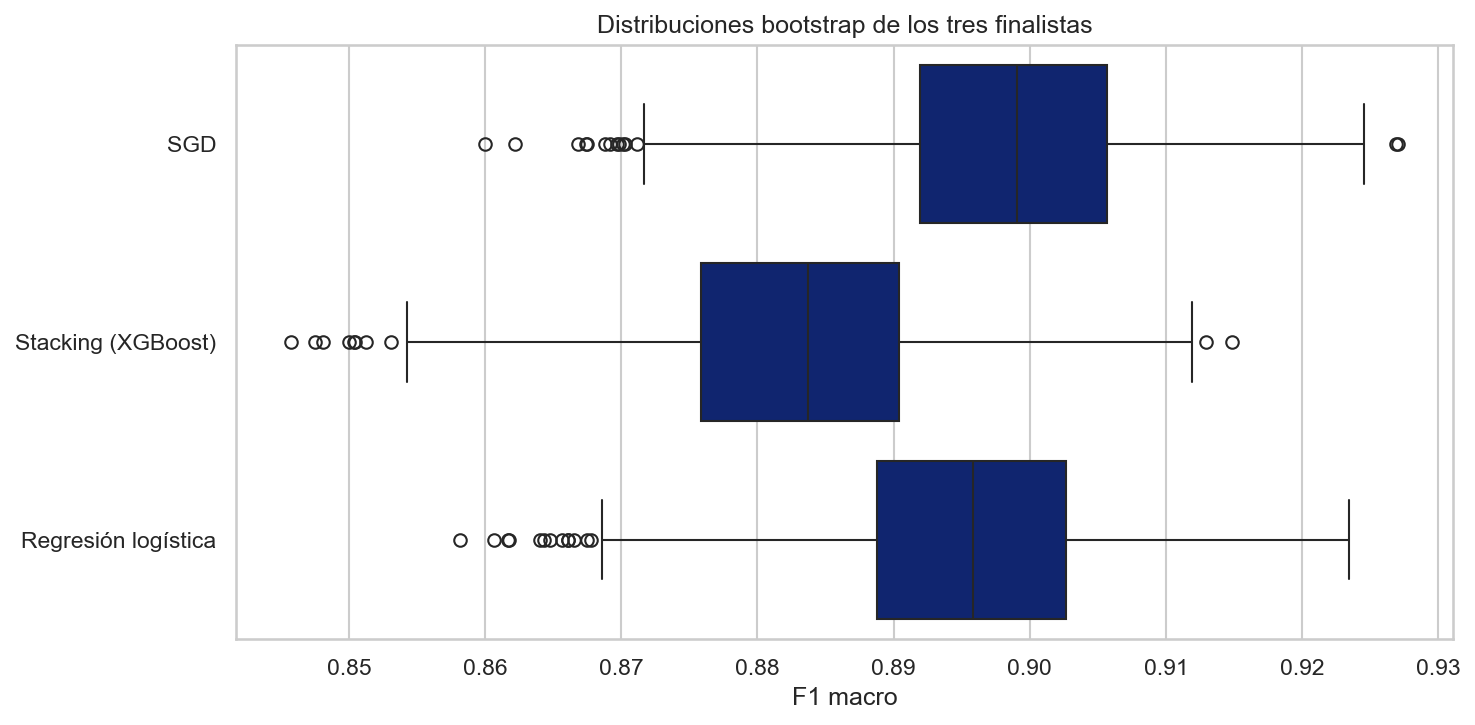

In [38]:
display(Image(filename='resultados/experiment003/12_bootstrap_distribuciones.png'))

## 4. Generalización y complejidad

### 4.1. ¿Importa la representación?

Primero se usa una regresión logística de referencia para aislar cada factor, manteniendo fijos datos, pliegues, limpieza y los restantes hiperparámetros. Se ejecutan estos estudios antes de consultar prueba. Las puntuaciones son de validación cruzada, no de prueba; las estimaciones de la mejor configuración tienen sesgo de selección.

Representación: TF-IDF logra el mayor F1 medio de CV (0.8984) con C=1. TF-IDF reduce el peso de términos frecuentes y la influencia de la longitud; BoW conserva el conteo absoluto. La diferencia observada puede depender del clasificador y su regularización.

### Tabla: representacion

In [39]:
tabla = pd.read_csv(RESULTADOS / 'experiment004' / 'representacion.csv')
tabla = tabla[['representacion', 'mean_train_score', 'mean_test_score', 'std_test_score']]
display(tabla.round(4))

,representacion,mean_train_score,mean_test_score,std_test_score
0,BoW,0.9999,0.8524,0.0083
1,TF-IDF,0.9954,0.8984,0.0070


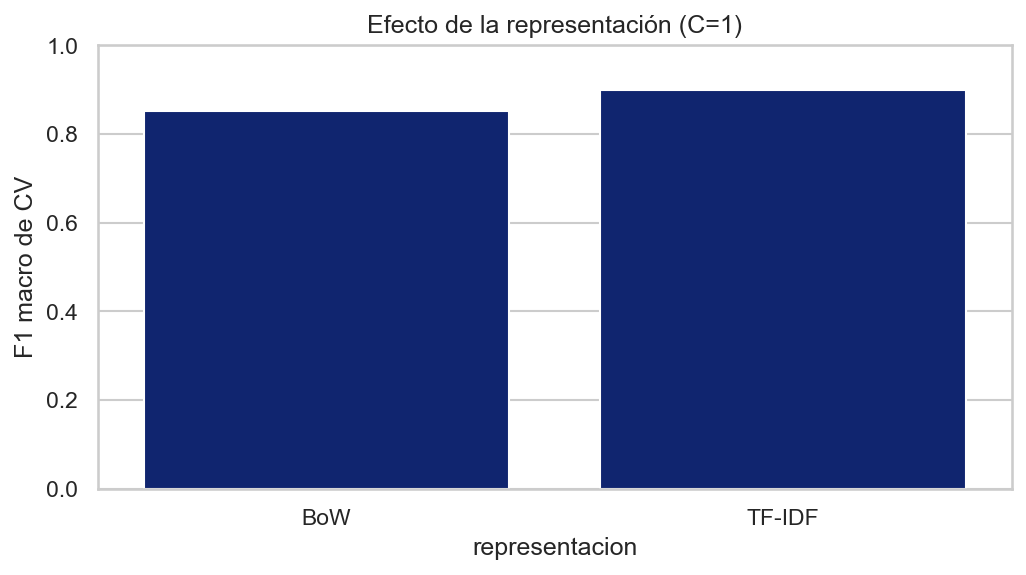

In [40]:
display(Image(filename='resultados/experiment004/01_representacion.png'))

### 4.2. ¿Cuánta dimensión necesitamos?

Dimensionalidad: el mejor máximo de vocabulario ensayado es 20,000 (F1=0.8989); es un límite, no necesariamente el número efectivo de columnas. En el estudio SVD, 200 componentes logran el mayor F1 (0.8864). Comprimir puede eliminar ruido, pero también vocabulario discriminativo. Comparar con TF-IDF sin reducir permite evaluar el costo de la compresión.

### Tabla: dimensionalidad

In [41]:
tabla = pd.read_csv(RESULTADOS / 'experiment004' / 'dimensionalidad.csv')
tabla = tabla[['caracteristicas_max', 'mean_train_score', 'mean_test_score']]
display(tabla.round(4))

,caracteristicas_max,mean_train_score,mean_test_score
0,1000,0.9549,0.8284
1,3000,0.9860,0.8751
2,10000,0.9954,0.8984
3,20000,0.9961,0.8989


### Tabla: componentes svd

In [42]:
tabla = pd.read_csv(RESULTADOS / 'experiment004' / 'componentes_svd.csv')
tabla = tabla[['componentes', 'mean_train_score', 'mean_test_score']]
display(tabla.round(4))

,componentes,mean_train_score,mean_test_score
0,25,0.8671,0.8681
1,50,0.8850,0.8735
2,100,0.9039,0.8809
3,200,0.9279,0.8864


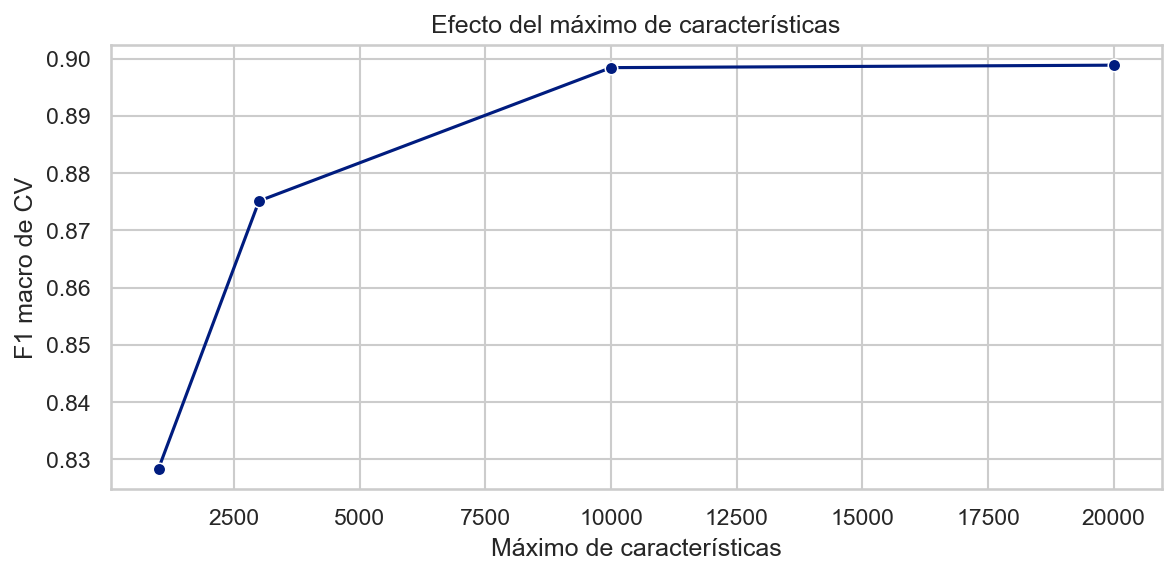

In [43]:
display(Image(filename='resultados/experiment004/02_dimensionalidad.png'))

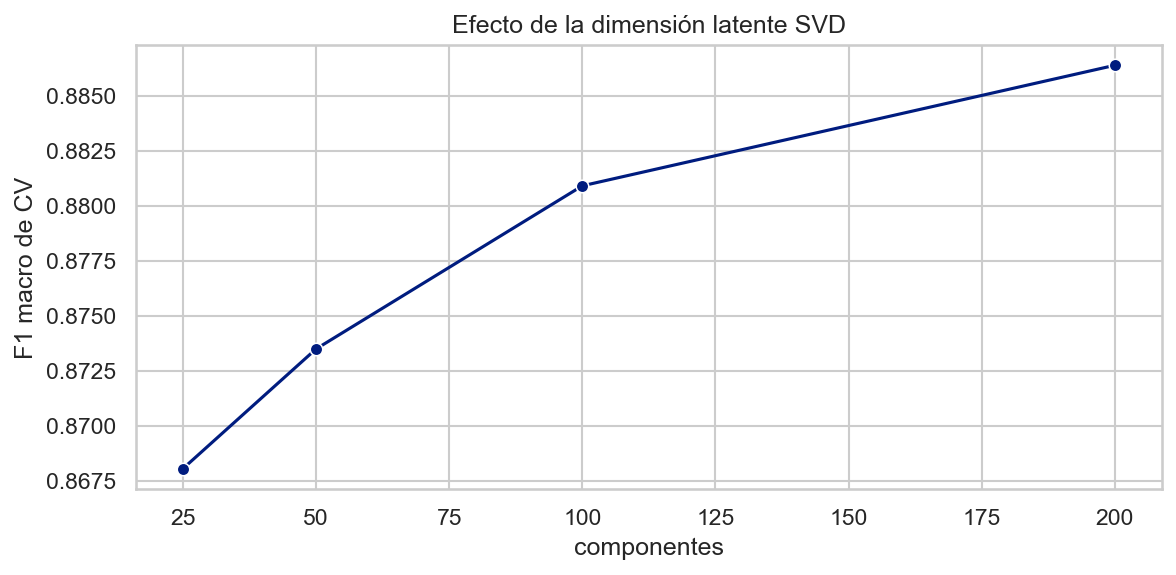

In [44]:
display(Image(filename='resultados/experiment004/03_componentes_svd.png'))

### 4.3. ¿Cuánta complejidad necesitamos?

Complejidad: C es el inverso de la fuerza de regularización. El mejor C exploratorio es 1 (F1=0.8984); la mayor brecha validación − entrenamiento en error 1−F1 es 0.1084 (C=1000). Una brecha positiva puede ser compatible con sobreajuste; una brecha pequeña con error alto puede ser compatible con subajuste. Esta curva no usa prueba.

### Tabla: complejidad

In [45]:
tabla = pd.read_csv(RESULTADOS / 'experiment004' / 'complejidad.csv')
tabla = tabla[['C', 'error_entrenamiento', 'error_validacion']]
display(tabla.round(4))

,C,error_entrenamiento,error_validacion
0,0.001,0.0329,0.1147
1,0.010,0.0315,0.1119
2,0.100,0.0255,0.1097
3,1.000,0.0046,0.1016
4,10.000,0.0000,0.1041
5,100.000,0.0000,0.1030
6,1000.000,0.0000,0.1084


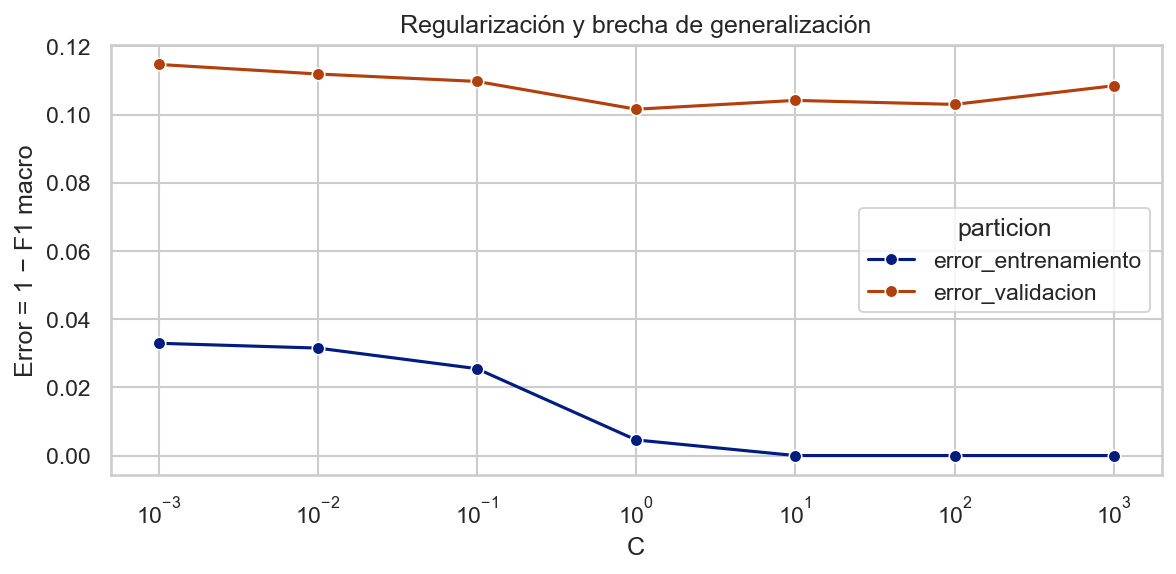

In [46]:
display(Image(filename='resultados/experiment004/04_complejidad.png'))

### 4.4. Integración: ¿aportan información los grupos?

Integración de aprendizaje no supervisado y supervisado (experiment006). La pregunta final es si la estructura temática aporta información útil además del vocabulario. Se conserva la rama léxica de cada uno de los diez candidatos y se añaden dos bloques de diez indicadores one-hot de pertenencia a grupos, obtenidos mediante K-means y mezcla gaussiana EM sobre SVD-50 normalizado. Se usa k=10, motivado por la exploración anterior, no se elige con el F1 de prueba. Los agrupamientos se reajustan sin etiquetas dentro de cada pliegue, incluido el stacking; ningún objeto ni asignación del capítulo 2 se reutiliza. DBSCAN y aglomerativo no ofrecen predict inductivo nativo y se excluyen de esta extensión.

Se repiten exactamente las familias, rejillas y cinco pliegues; la mayor ganancia en CV corresponde a AdaBoost (+0.1279). Mejoran 4 de diez candidatos por CV. El ranking conjunto de veinte candidatos sitúa primero a SGD (Léxica, F1 CV=0.9008). En prueba histórica se rechazan 7 de diez contrastes pareados híbrido contra referencia tras Holm. El top tres global tiene 1 contrastes rechazados de tres; constituye una familia separada.

Advertencia: experiment006 se diseñó después de observar la prueba original. Aunque los nuevos ajustes no utilizan sus etiquetas ni sus documentos, esta segunda evaluación es exploratoria y no una confirmación independiente; haría falta otro conjunto externo. Los IC son marginales y las correcciones Holm se aplican por familia.

### Tabla: comparacion

In [47]:
tabla = pd.read_csv(RESULTADOS / 'experiment006' / 'comparacion.csv')
tabla = tabla[['modelo', 'F1_CV_base', 'F1_CV_hibrido', 'delta_CV', 'delta_prueba', 'factor_tiempo']]
display(tabla.round(4))

,modelo,F1_CV_base,F1_CV_hibrido,delta_CV,delta_prueba,factor_tiempo
0,AdaBoost,0.6563,0.7842,0.1279,0.1446,1.1562
1,Árbol de decisión,0.6994,0.7777,0.0783,0.0806,1.2903
2,Gradient Boosting,0.8451,0.8509,0.0058,0.0163,1.4627
3,Random Forest,0.8322,0.8338,0.0016,-0.0105,0.9741
4,SGD,0.9008,0.8711,-0.0297,-0.0335,3.0608
5,Stacking (XGBoost),0.9001,0.8644,-0.0357,-0.0191,1.1217
6,Regresión logística,0.8984,0.8609,-0.0376,-0.0545,2.3677
7,SVM RBF,0.8964,0.8491,-0.0473,-0.0543,0.7411
8,Votación (7 modelos),0.8923,0.8341,-0.0582,-0.0708,1.0850
9,Bagging (regresión logística),0.8963,0.8240,-0.0724,-0.0879,1.3930


### Tabla: bootstrap holm

In [48]:
tabla = pd.read_csv(RESULTADOS / 'experiment006' / 'bootstrap_holm.csv')
tabla = tabla[['modelo', 'delta_F1', 'IC_inferior', 'IC_superior', 'p_Holm']]
display(tabla.round(4))

,modelo,delta_F1,IC_inferior,IC_superior,p_Holm
0,AdaBoost,0.1446,0.1148,0.1755,0.0050
1,Árbol de decisión,0.0806,0.0494,0.1144,0.0050
2,Gradient Boosting,0.0163,0.0021,0.0310,0.0855
3,Random Forest,-0.0105,-0.0306,0.0107,0.3333
4,Stacking (XGBoost),-0.0191,-0.0360,-0.0016,0.0855
5,SGD,-0.0335,-0.0508,-0.0168,0.0050
6,SVM RBF,-0.0543,-0.0740,-0.0354,0.0050
7,Regresión logística,-0.0545,-0.0727,-0.0374,0.0050
8,Votación (7 modelos),-0.0708,-0.0921,-0.0507,0.0050
9,Bagging (regresión logística),-0.0879,-0.1098,-0.0682,0.0050


### Tabla: ranking global

In [49]:
tabla = pd.read_csv(RESULTADOS / 'experiment006' / 'ranking_global.csv')
tabla = tabla[['modelo', 'representacion', 'F1_CV', 'F1', 'segundos']]
display(tabla.round(4))

,modelo,representacion,F1_CV,F1,segundos
0,SGD,Léxica,0.9008,0.8991,0.6490
1,Stacking (XGBoost),Léxica,0.9001,0.8838,216.1715
2,Regresión logística,Léxica,0.8984,0.8959,1.1697
3,SVM RBF,Léxica,0.8964,0.8922,6.0373
4,Bagging (regresión logística),Léxica,0.8963,0.9003,6.4283
5,Votación (7 modelos),Léxica,0.8923,0.8964,43.7274
6,SGD,Léxica + grupos,0.8711,0.8656,1.9866
7,Stacking (XGBoost),Léxica + grupos,0.8644,0.8647,242.4879
8,Regresión logística,Léxica + grupos,0.8609,0.8415,2.7696
9,Gradient Boosting,Léxica + grupos,0.8509,0.8747,25.4760


### Tabla: bootstrap finalistas

In [50]:
tabla = pd.read_csv(RESULTADOS / 'experiment006' / 'bootstrap_finalistas.csv')
tabla = tabla[['modelo_A', 'modelo_B', 'delta_F1', 'p_Holm']]
display(tabla.round(4))

,modelo_A,modelo_B,delta_F1,p_Holm
0,SGD,Stacking (XGBoost),0.0153,0.0345
1,SGD,Regresión logística,0.0032,0.3578
2,Stacking (XGBoost),Regresión logística,-0.0122,0.0650


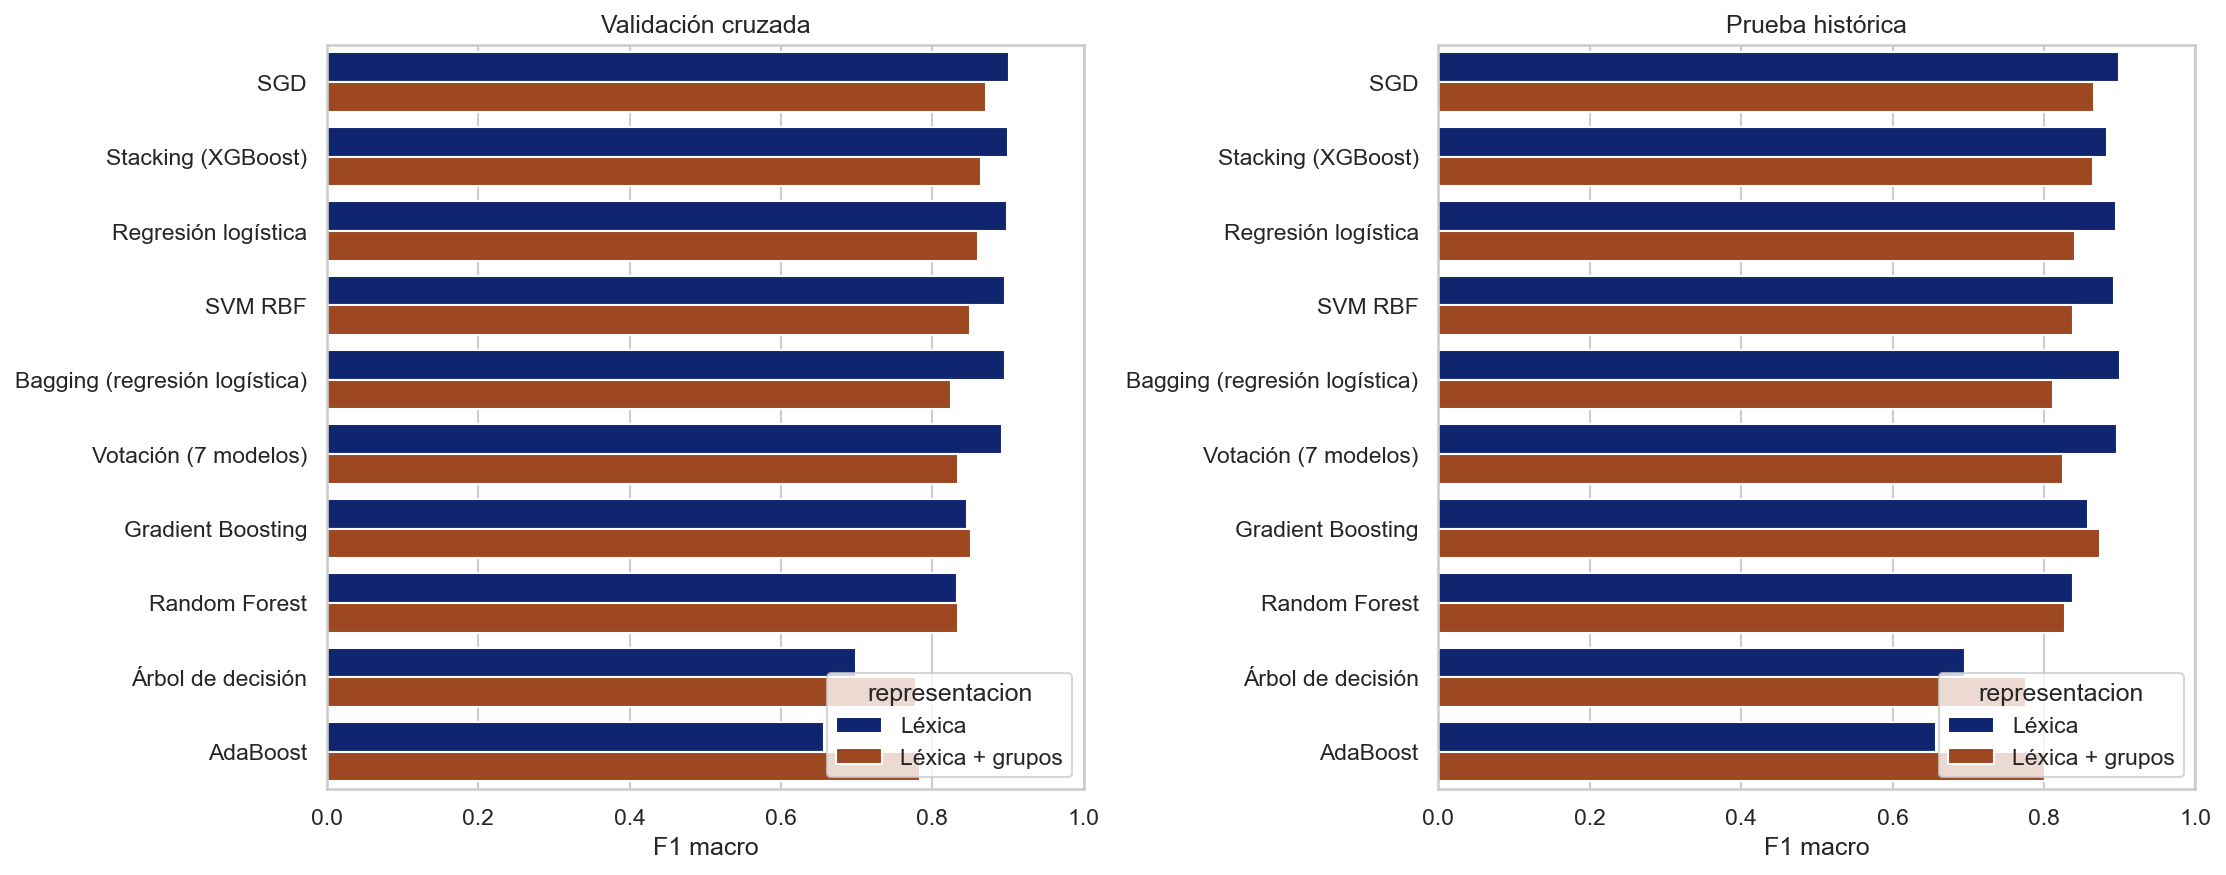

In [51]:
display(Image(filename='resultados/experiment006/01_comparacion_pareada.png'))

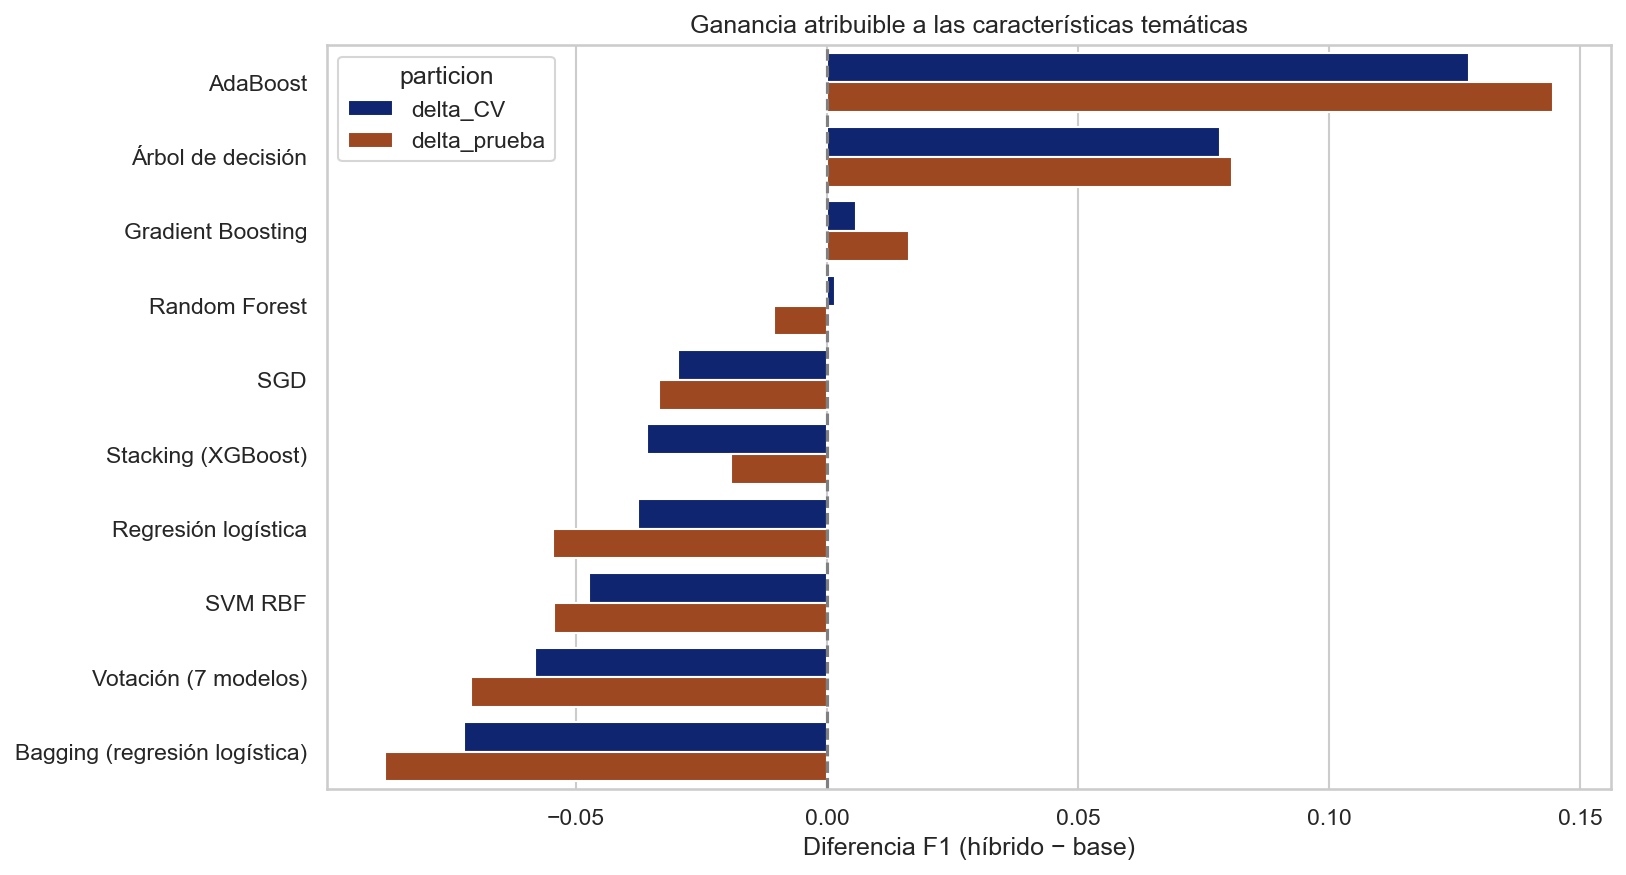

In [52]:
display(Image(filename='resultados/experiment006/02_ganancia.png'))

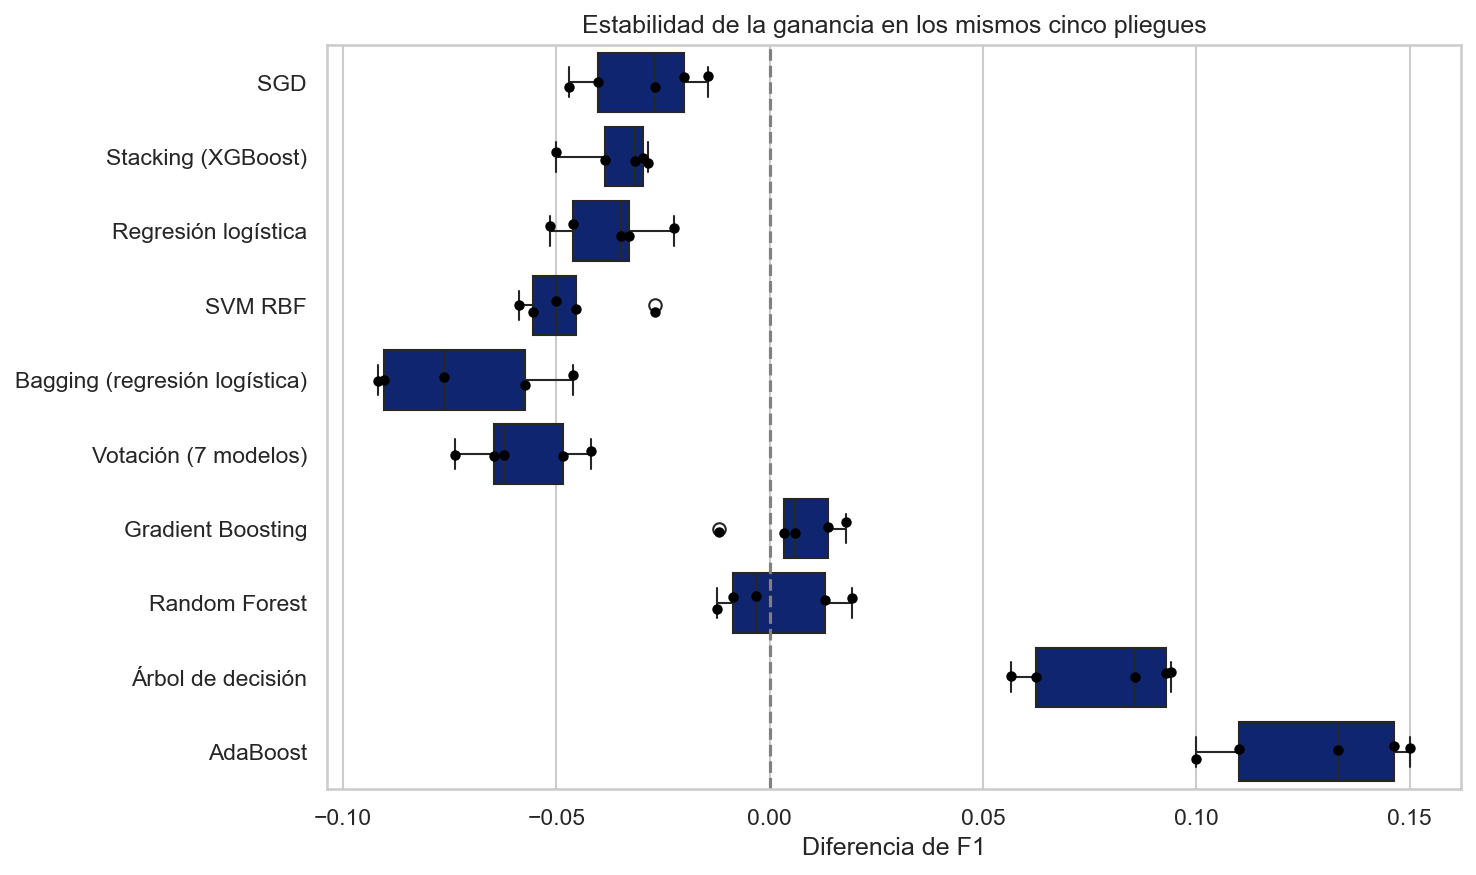

In [53]:
display(Image(filename='resultados/experiment006/03_estabilidad_ganancia.png'))

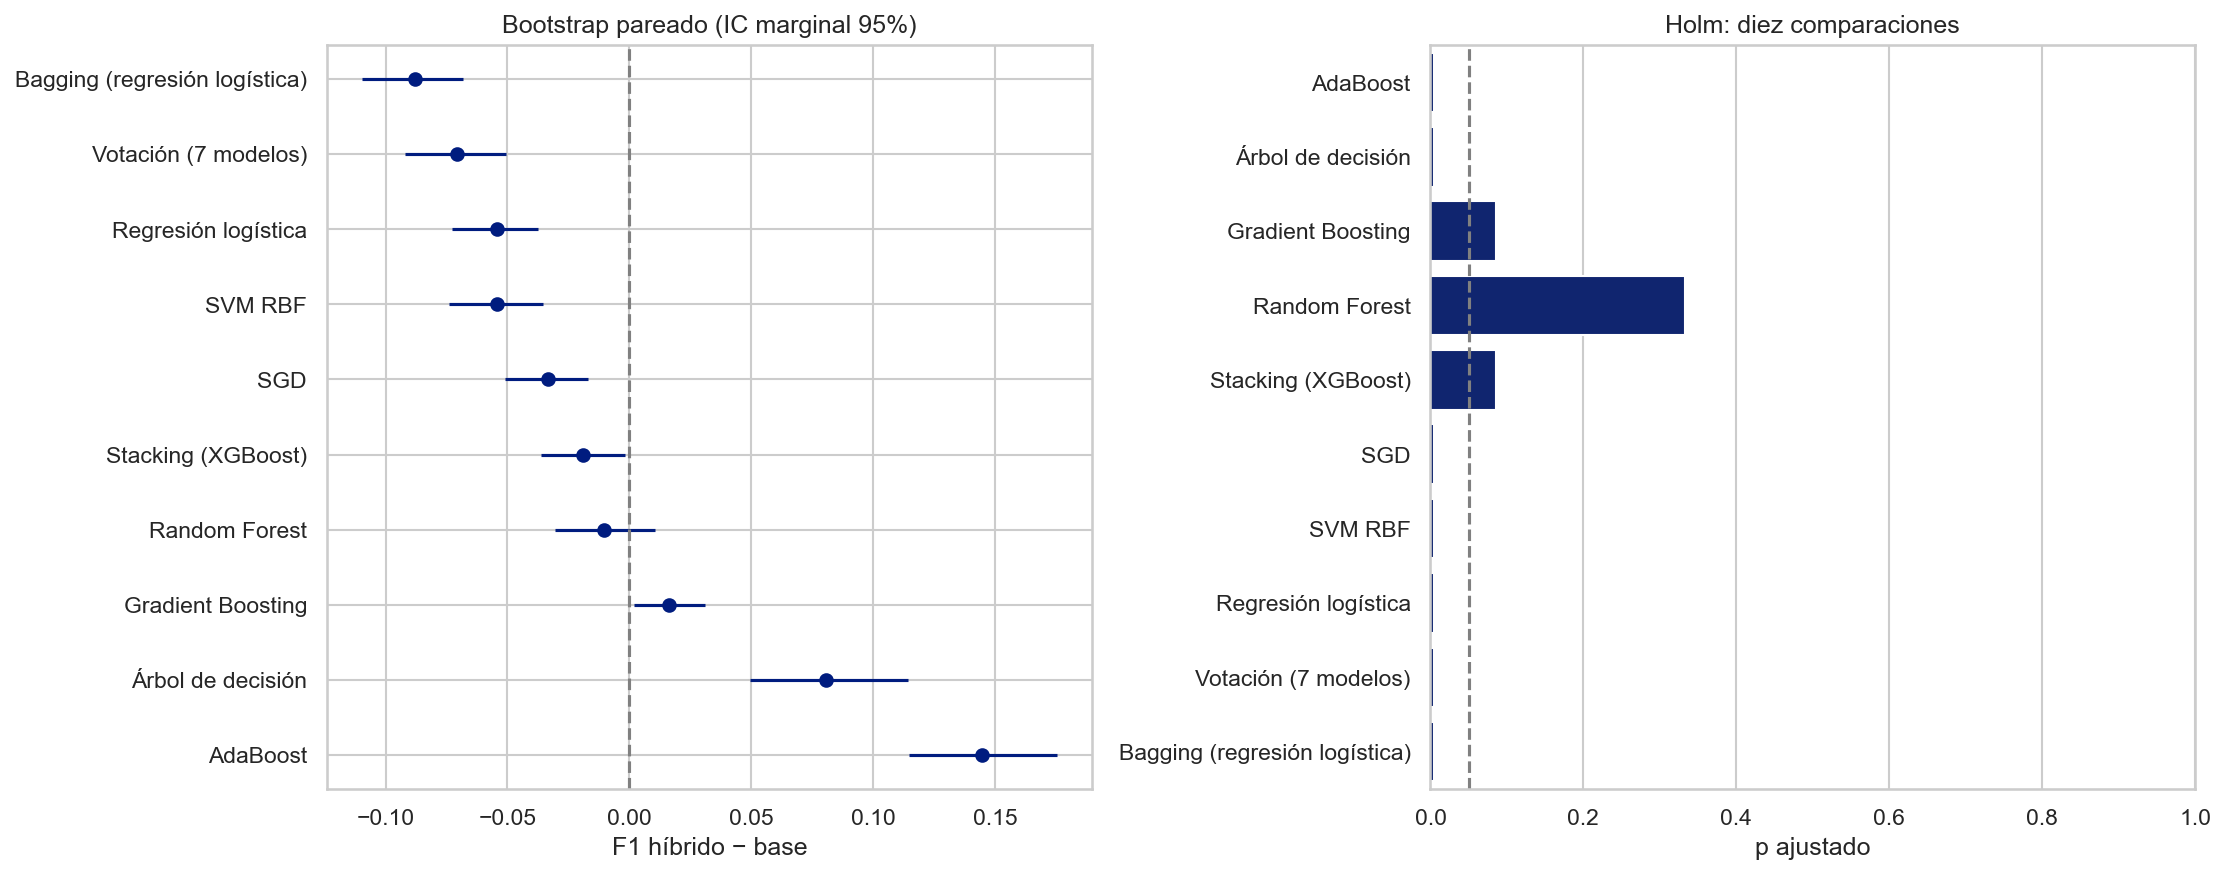

In [54]:
display(Image(filename='resultados/experiment006/04_bootstrap_holm.png'))

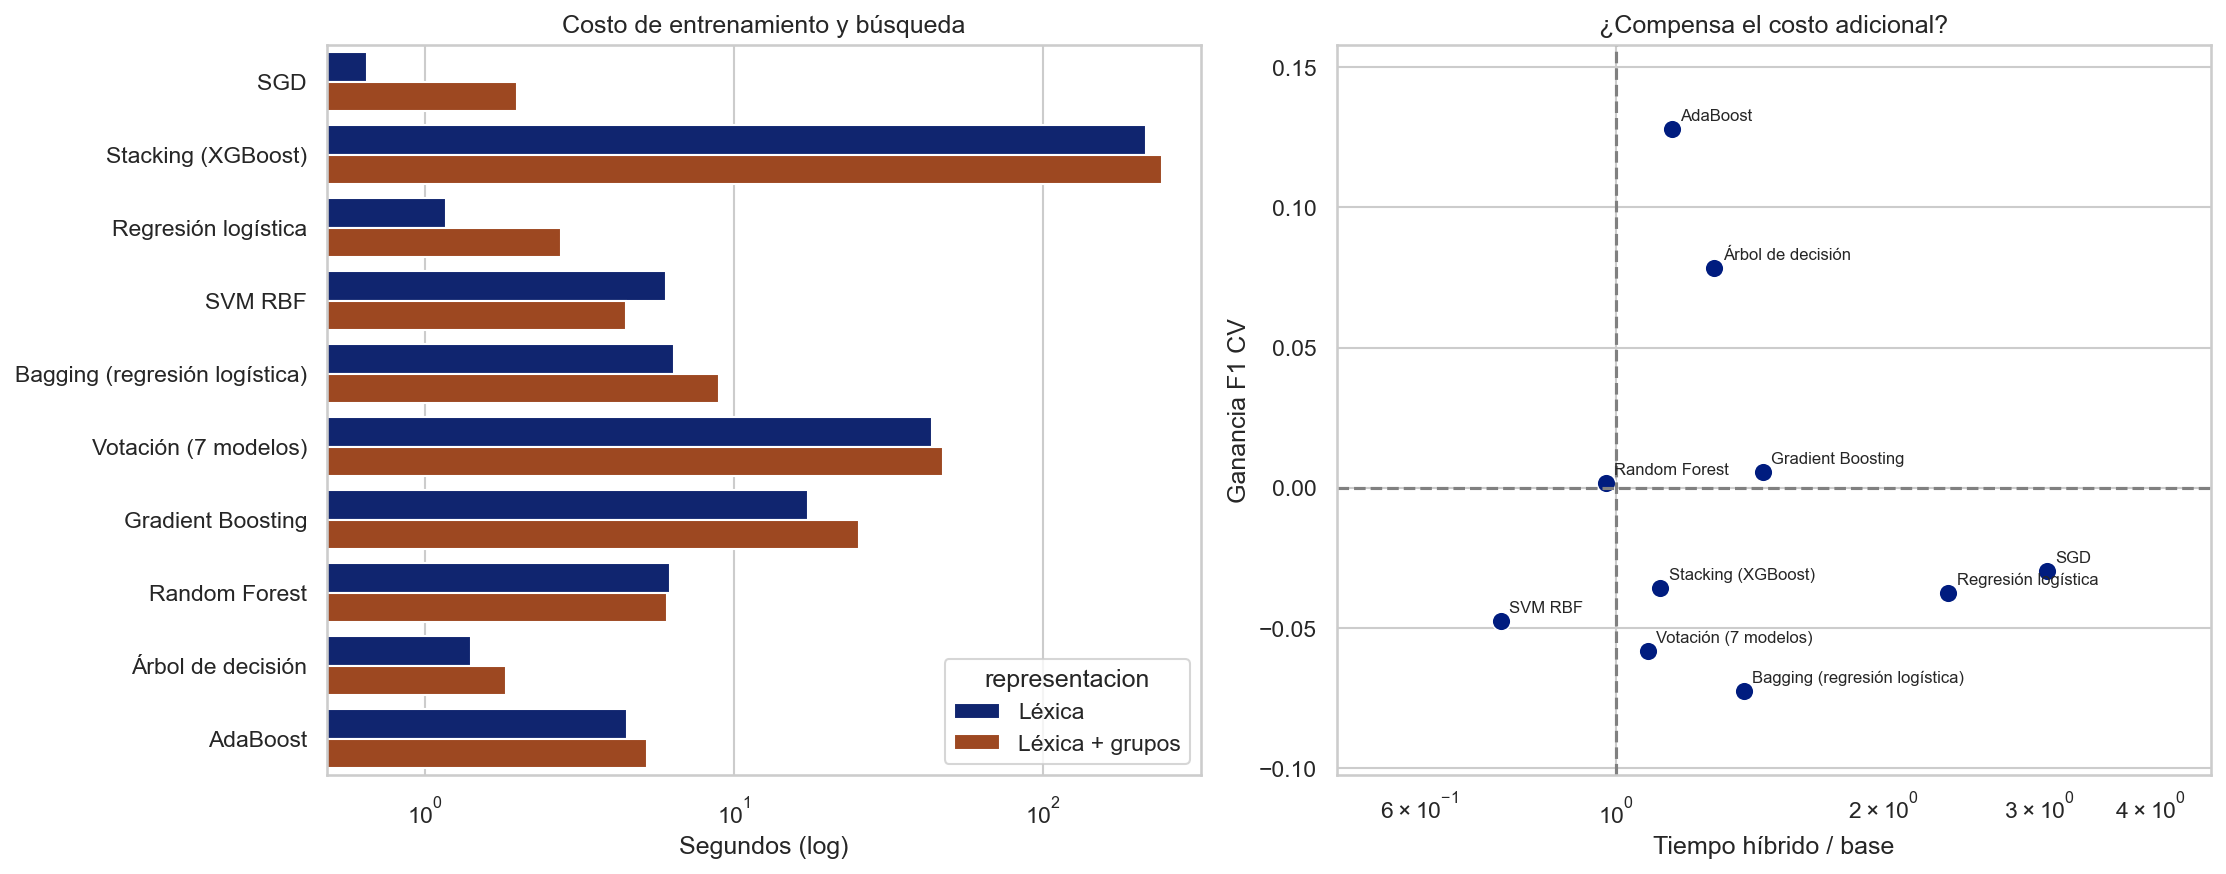

In [55]:
display(Image(filename='resultados/experiment006/05_costo_ganancia.png'))

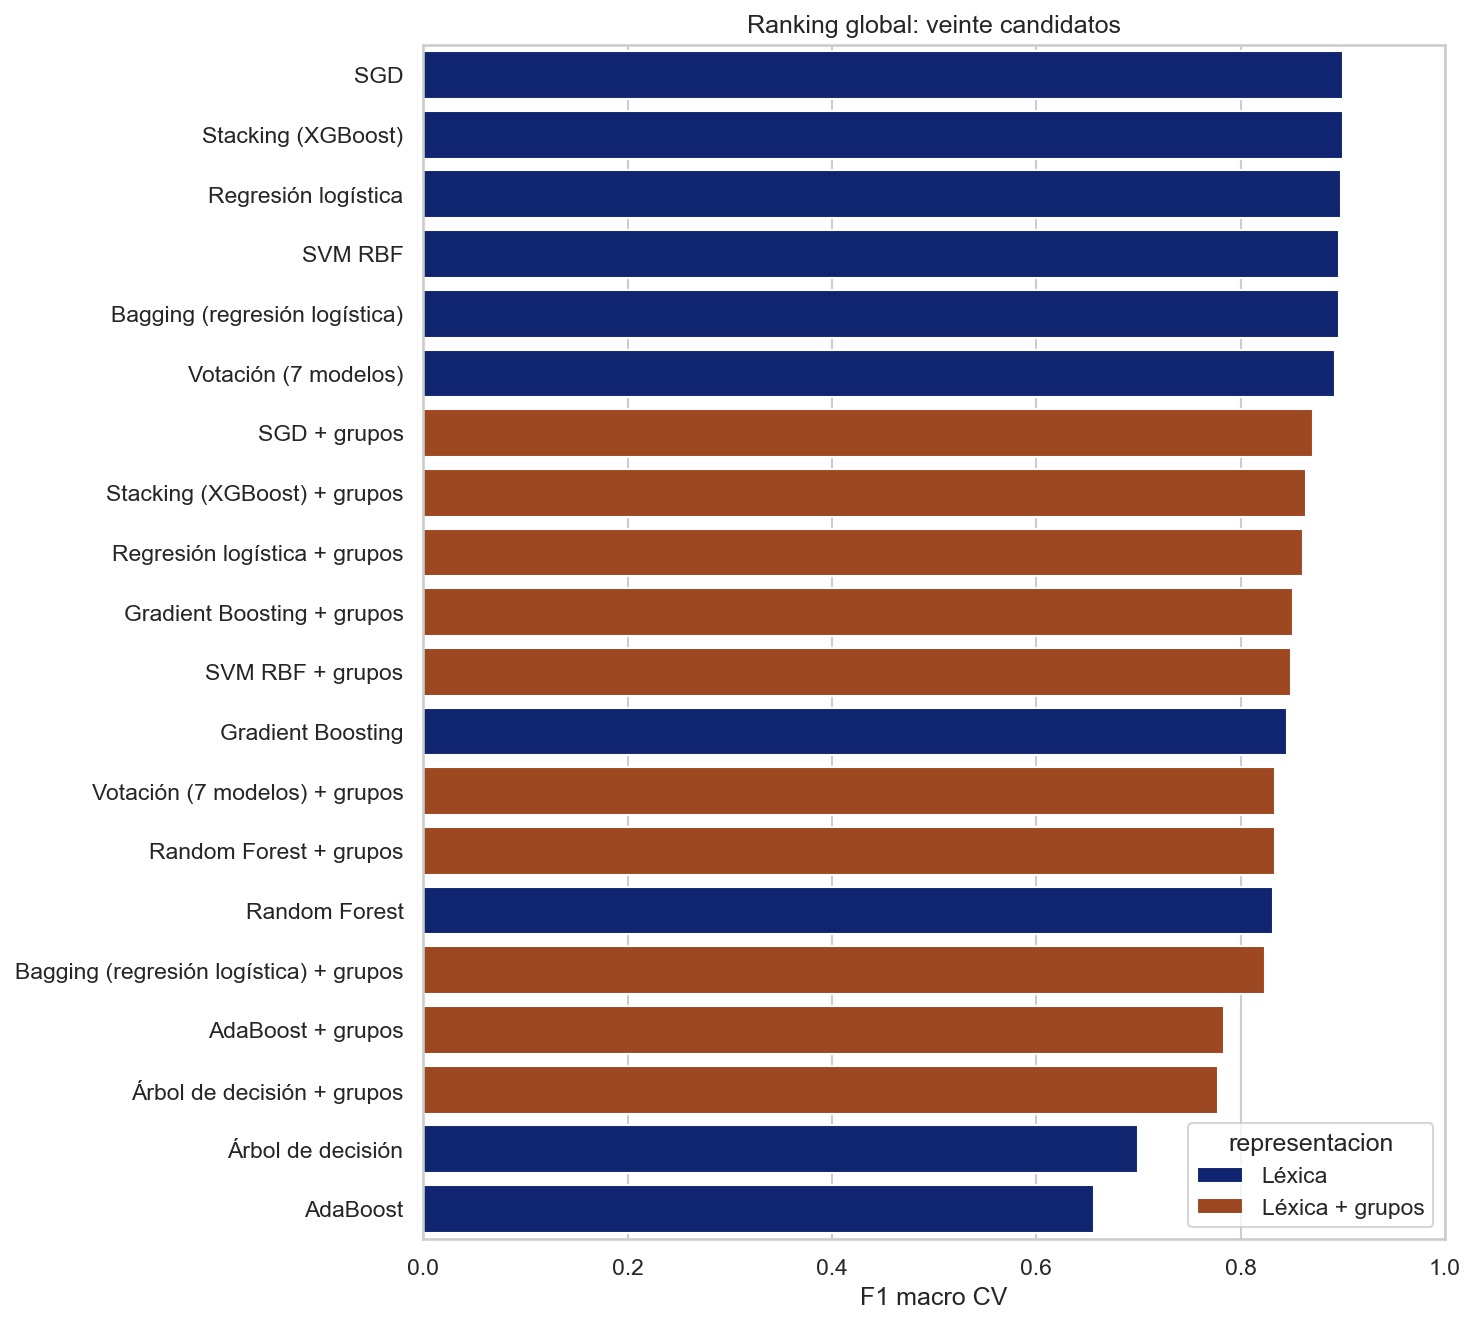

In [56]:
display(Image(filename='resultados/experiment006/06_ranking_global.png'))

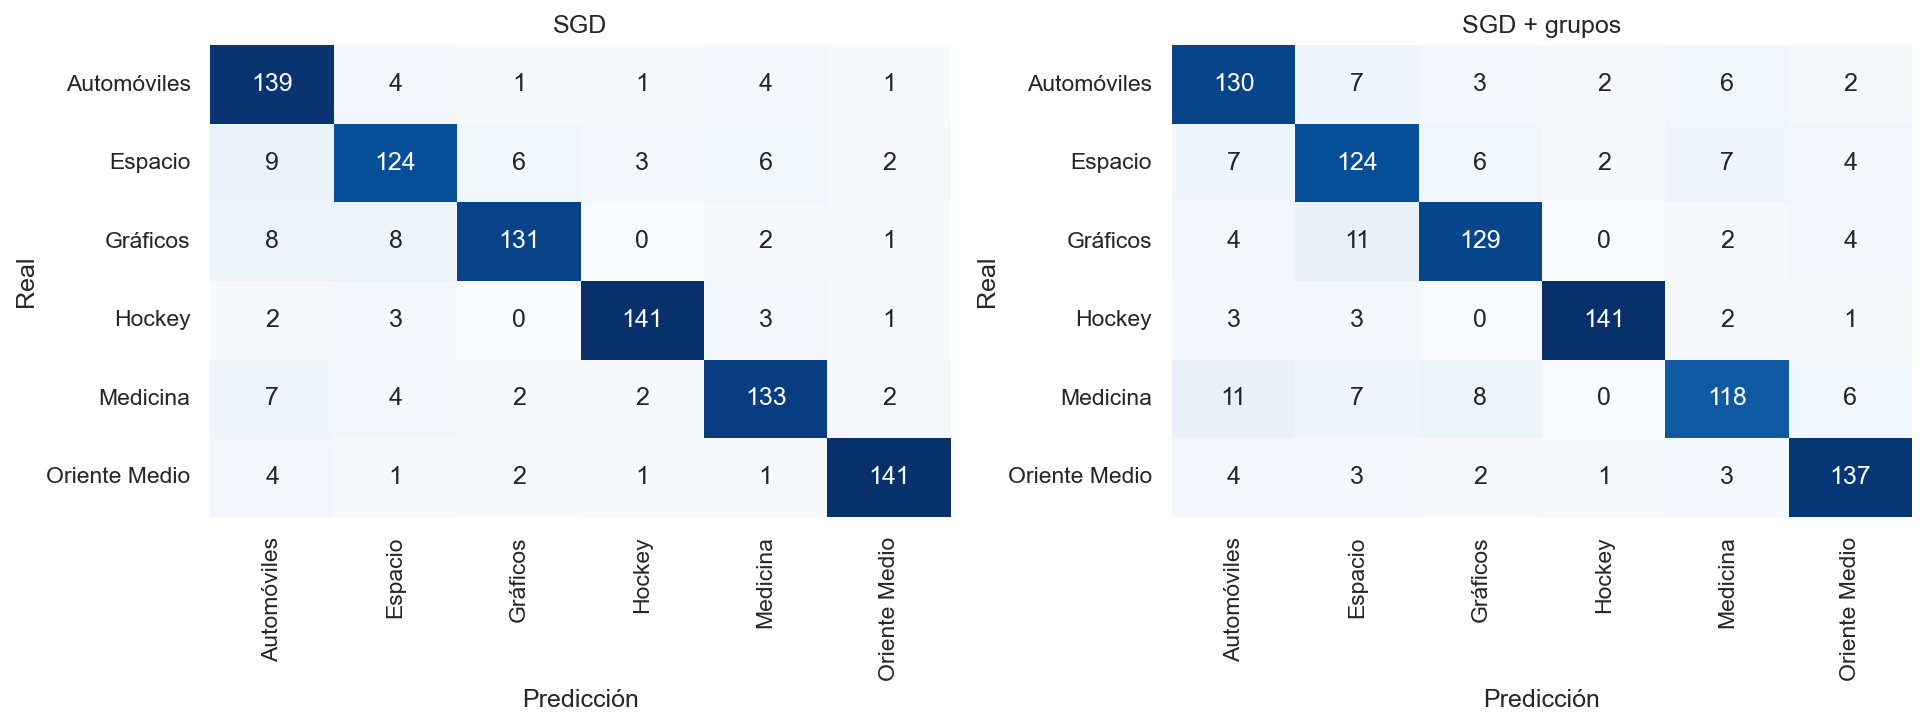

In [57]:
display(Image(filename='resultados/experiment006/07_confusiones_finalistas.png'))

## 5. Discusión y conclusiones

La clasificación supervisada y el agrupamiento resuelven problemas distintos: el primero aprende etiquetas y obtiene F1 de prueba 0.8991 con SGD; el segundo recupera estructura no etiquetada y obtiene ARI 0.4332 para la configuración elegida internamente. Las escalas y objetivos de ambas métricas son diferentes, por lo que no se deben restar ni comparar como si midieran lo mismo.

En los estudios controlados, la mejor representación fue TF-IDF, el mejor máximo de vocabulario fue 20,000, la mejor dimensión latente ensayada fue 200 y el mejor C exploratorio fue 1. Son conclusiones locales a los rangos y al modelo de referencia, no óptimos universales. El modelo de referencia se escogió por CV, no por su posición en prueba. El ranking exploratorio ampliado selecciona SGD (Léxica); su evaluación sobre la prueba ya observada requiere confirmación externa.

Limitaciones: corpus histórico en inglés, seis temas seleccionados y balance artificial; eliminación de duplicados exactos sin garantía de independencia entre hilos relacionados; una sola partición oficial, búsqueda de hiperparámetros limitada, posibles documentos casi vacíos tras eliminar palabras funcionales, y representación léxica sin orden ni semántica contextual. El bootstrap no refleja la variabilidad del entrenamiento ni la deriva temporal. Una extensión sería evaluar todos los temas, particiones agrupadas por hilo, n-gramas, embeddings y validación en otro corpus; no debe reajustarse el modelo con la prueba ya evaluada.

Fuente de datos y metodología de descarga: scikit-learn, The 20 newsgroups text dataset, https://scikit-learn.org/stable/datasets/real_world.html#the-20-newsgroups-text-dataset. Las tablas completas, configuraciones, predicciones, réplicas y código se conservan en el repositorio.